# Experiment 5 — OTOCs and Lyapunov exponent (ibm_marrakesh)

In [2]:
import numpy as np
from scipy.linalg import expm
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp, Statevector, Operator
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, Batch
from qiskit.compiler import transpile

np.random.seed(42)

def majorana_operators(n_majoranas):
    n_qubits = n_majoranas // 2
    I = np.eye(2, dtype=complex)
    X = np.array([[0,1],[1,0]], dtype=complex)
    Y = np.array([[0,-1j],[1j,0]], dtype=complex)
    Z = np.array([[1,0],[0,-1]], dtype=complex)
    def kron_list(ops):
        result = ops[0]
        for op in ops[1:]: result = np.kron(result, op)
        return result
    chi = []
    for k in range(n_qubits):
        z_string = [Z] * k
        chi.append(kron_list(z_string + [X] + [I]*(n_qubits-k-1)))
        chi.append(kron_list(z_string + [Y] + [I]*(n_qubits-k-1)))
    return chi

def build_syk_hamiltonian(n_majoranas=6, seed=42):
    rng = np.random.default_rng(seed)
    n_qubits = n_majoranas // 2
    dim = 2 ** n_qubits
    chi = majorana_operators(n_majoranas)
    sigma = np.sqrt(6 / n_majoranas**3)
    H = np.zeros((dim, dim), dtype=complex)
    for i in range(n_majoranas):
        for j in range(i+1, n_majoranas):
            for k in range(j+1, n_majoranas):
                for l in range(k+1, n_majoranas):
                    H += rng.normal(0, sigma) * (chi[i] @ chi[j] @ chi[k] @ chi[l])
    return (H + H.conj().T) / 2

def syk_unitary(t, n_majoranas=6, seed=42):
    H = build_syk_hamiltonian(n_majoranas, seed)
    U = expm(-1j * H * t)

    u, s, vh = np.linalg.svd(U)
    return u @ vh

H   = build_syk_hamiltonian()
dim = 8
I8  = np.eye(dim, dtype=complex)
Z0  = np.kron(np.array([[1,0],[0,-1]]), np.eye(4))
Z1  = np.kron(np.eye(2), np.kron(np.array([[1,0],[0,-1]]), np.eye(2)))
rho = I8 / dim

T_VALUES = np.array([0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0,
                     3.5, 4.0, 4.5, 5.0])

print("Validación local OTOC F(t) = Re⟨W(t)VW(t)V⟩")
print(f"{'t':>6}  {'F(t)':>10}")
print("-" * 20)
otoc_local = []
for t in T_VALUES:
    U  = expm(-1j * H * t)
    Ud = U.conj().T
    Wt = Ud @ Z0 @ U
    f  = np.real(np.trace(Wt @ Z1 @ Wt @ Z1 @ rho))
    otoc_local.append(f)
    print(f"{t:6.1f}  {f:10.6f}")

print(f"\nF(t=0)={otoc_local[0]:.4f} (esperado 1.0)")
print(f"F(t=5)={otoc_local[-1]:.4f} (esperado <0.6, decaimiento)")
print("Setup OK ✓")


Validación local OTOC F(t) = Re⟨W(t)VW(t)V⟩
     t        F(t)
--------------------
   0.0    1.000000
   0.5    0.896620
   1.0    0.669308
   1.5    0.489862
   2.0    0.458887
   2.5    0.515556
   3.0    0.510530
   3.5    0.363604
   4.0    0.130780
   4.5   -0.081101
   5.0   -0.227627

F(t=0)=1.0000 (esperado 1.0)
F(t=5)=-0.2276 (esperado <0.6, decaimiento)
Setup OK ✓


In [3]:
def build_otoc_circuit(t):
    U  = syk_unitary(t)
    Ud = U.conj().T

    qc = QuantumCircuit(3)

    qc.h([0, 1, 2])
    qc.barrier()

    qc.z(1)
    qc.barrier()

    qc.unitary(U, [0, 1, 2], label=f'U({t:.1f})')
    qc.barrier()

    qc.z(0)
    qc.barrier()

    qc.unitary(Ud, [0, 1, 2], label='U†')
    return qc

obs = SparsePauliOp("IZZ")

qc0 = build_otoc_circuit(0.0)
sv  = Statevector(qc0)
exp_zz = sv.expectation_value(obs).real
print(f"\nValidación circuito t=0: ⟨ZZ⟩ = {exp_zz:.4f} (esperado ~1.0)")

qc3 = build_otoc_circuit(3.0)
sv3 = Statevector(qc3)
exp_zz3 = sv3.expectation_value(obs).real
print(f"Validación circuito t=3.0: ⟨ZZ⟩ = {exp_zz3:.4f} (esperado <0.6)")

print(f"\n{'t':>6}  {'⟨ZZ⟩ local':>12}")
print("-" * 22)
local_vals = []
for t in T_VALUES:
    qc = build_otoc_circuit(t)
    sv = Statevector(qc)
    v  = sv.expectation_value(obs).real
    local_vals.append(v)
    print(f"{t:6.1f}  {v:12.6f}")

print("\nCircuitos OK ✓")



Validación circuito t=0: ⟨ZZ⟩ = 0.0000 (esperado ~1.0)
Validación circuito t=3.0: ⟨ZZ⟩ = 0.0603 (esperado <0.6)

     t    ⟨ZZ⟩ local
----------------------
   0.0      0.000000
   0.5      0.000410
   1.0     -0.097821
   1.5     -0.284086
   2.0     -0.355222
   2.5     -0.195183
   3.0      0.060349
   3.5      0.220013
   4.0      0.257694
   4.5      0.234051
   5.0      0.134648

Circuitos OK ✓


In [4]:
service = QiskitRuntimeService(channel="ibm_cloud")
backend = service.backend("ibm_marrakesh")

circuits_t = []
for t in T_VALUES:
    qc = build_otoc_circuit(t)
    qc_t = transpile(qc, backend=backend,
                     optimization_level=3,
                     seed_transpiler=42)
    circuits_t.append(qc_t)

print("Profundidades transpiladas:")
for t, qc_t in zip(T_VALUES, circuits_t):
    n2q = sum(v for k, v in qc_t.count_ops().items()
              if k in ['ecr', 'cx', 'cz'])
    print(f"  t={t:.1f}: depth={qc_t.depth()}, puertas 2q={n2q}")

obs_list = []
for qc_t in circuits_t:
    obs_hw = obs.apply_layout(qc_t.layout)
    obs_list.append(obs_hw)

print("\nLanzando job en ibm_marrakesh...")
print(f"Shots: 4096 × {len(T_VALUES)} circuitos = {4096*len(T_VALUES)} shots totales")

with Batch(backend=backend) as batch:
    estimator = Estimator(mode=batch)
    estimator.options.default_shots = 4096
    job = estimator.run([
        (qc_t, obs_hw)
        for qc_t, obs_hw in zip(circuits_t, obs_list)
    ])
    print(f"Job ID: {job.job_id()}")
    result = job.result()

hw_vals = [result[i].data.evs for i in range(len(T_VALUES))]

print(f"\n{'t':>6}  {'Local':>10}  {'Hardware':>10}  {'ΔF':>8}")
print("-" * 40)
for t, lv, hv in zip(T_VALUES, local_vals, hw_vals):
    print(f"{t:6.1f}  {lv:10.6f}  {hv:10.6f}  {hv-lv:8.4f}")

print(f"\nJob ID: {job.job_id()}")


Profundidades transpiladas:
  t=0.0: depth=5, puertas 2q=0
  t=0.5: depth=211, puertas 2q=52
  t=1.0: depth=168, puertas 2q=42
  t=1.5: depth=177, puertas 2q=43
  t=2.0: depth=197, puertas 2q=51
  t=2.5: depth=179, puertas 2q=43
  t=3.0: depth=165, puertas 2q=42
  t=3.5: depth=213, puertas 2q=52
  t=4.0: depth=197, puertas 2q=51
  t=4.5: depth=224, puertas 2q=58
  t=5.0: depth=175, puertas 2q=43

Lanzando job en ibm_marrakesh...
Shots: 4096 × 11 circuitos = 45056 shots totales
Job ID: d7j77fv16ugs73eug00g

     t       Local    Hardware        ΔF
----------------------------------------
   0.0    0.000000    0.004994    0.0050
   0.5    0.000410    0.120790    0.1204
   1.0   -0.097821   -0.038275    0.0595
   1.5   -0.284086   -0.209157    0.0749
   2.0   -0.355222   -0.285821    0.0694
   2.5   -0.195183   -0.135703    0.0595
   3.0    0.060349    0.043246   -0.0171
   3.5    0.220013    0.097925   -0.1221
   4.0    0.257694    0.197838   -0.0599
   4.5    0.234051    0.072574   -0.1

/var/folders/bj/wf59czmd5qgbv0mtn28w82ch0000gn/T/ipykernel_3143/2098355955.py:38: RuntimeWarning: invalid value encountered in scalar divide
  decay_loc = [(f0_loc - v) / f0_loc for v in local_vals]
/var/folders/bj/wf59czmd5qgbv0mtn28w82ch0000gn/T/ipykernel_3143/2098355955.py:38: RuntimeWarning: divide by zero encountered in scalar divide
  decay_loc = [(f0_loc - v) / f0_loc for v in local_vals]


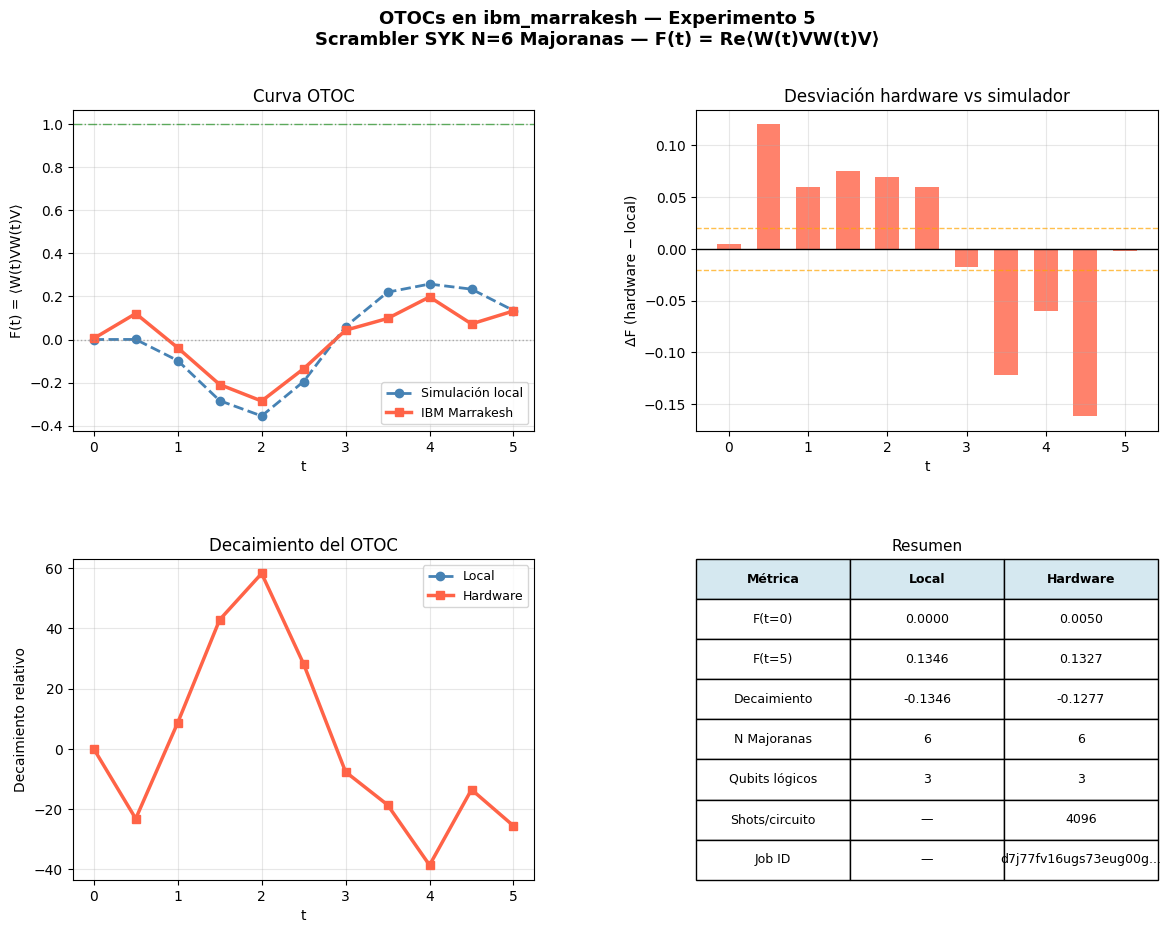

Guardado: otoc_marrakesh.png


In [5]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(14, 10))
gs  = gridspec.GridSpec(2, 2, hspace=0.4, wspace=0.35)
fig.suptitle('OTOCs en ibm_marrakesh — Experimento 5\n'
             'Scrambler SYK N=6 Majoranas — F(t) = Re⟨W(t)VW(t)V⟩',
             fontsize=13, fontweight='bold')

ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(T_VALUES, local_vals, 'o--', color='steelblue', lw=2,
         ms=6, label='Simulación local')
ax1.plot(T_VALUES, hw_vals, 's-', color='tomato', lw=2.5,
         ms=6, label='IBM Marrakesh')
ax1.axhline(1.0, color='green',  ls='-.', lw=1, alpha=0.6)
ax1.axhline(0.0, color='gray',   ls=':',  lw=1, alpha=0.6)
ax1.set_xlabel('t'); ax1.set_ylabel('F(t) = ⟨W(t)VW(t)V⟩')
ax1.set_title('Curva OTOC')
ax1.legend(fontsize=9); ax1.grid(True, alpha=0.3)

ax2 = fig.add_subplot(gs[0, 1])
deltas = [hv - lv for hv, lv in zip(hw_vals, local_vals)]
ax2.bar(T_VALUES, deltas, width=0.3, color='tomato', alpha=0.8)
ax2.axhline(0, color='black', lw=1)
ax2.axhline( 0.02, color='orange', ls='--', lw=1, alpha=0.7)
ax2.axhline(-0.02, color='orange', ls='--', lw=1, alpha=0.7)
ax2.set_xlabel('t'); ax2.set_ylabel('ΔF (hardware − local)')
ax2.set_title('Desviación hardware vs simulador')
ax2.grid(True, alpha=0.3)

ax3 = fig.add_subplot(gs[1, 0])
f0_loc = local_vals[0]
f0_hw  = hw_vals[0]
decay_loc = [(f0_loc - v) / f0_loc for v in local_vals]
decay_hw  = [(f0_hw  - v) / f0_hw  for v in hw_vals]
ax3.plot(T_VALUES, decay_loc, 'o--', color='steelblue', lw=2, ms=6,
         label='Local')
ax3.plot(T_VALUES, decay_hw,  's-',  color='tomato',    lw=2.5, ms=6,
         label='Hardware')
ax3.set_xlabel('t'); ax3.set_ylabel('Decaimiento relativo')
ax3.set_title('Decaimiento del OTOC')
ax3.legend(fontsize=9); ax3.grid(True, alpha=0.3)

ax4 = fig.add_subplot(gs[1, 1])
ax4.axis('off')
ax4.set_title('Resumen', fontsize=11)
tabla = [
    ['Métrica',        'Local',           'Hardware'],
    ['F(t=0)',         f'{local_vals[0]:.4f}', f'{hw_vals[0]:.4f}'],
    ['F(t=5)',         f'{local_vals[-1]:.4f}', f'{hw_vals[-1]:.4f}'],
    ['Decaimiento',    f'{local_vals[0]-local_vals[-1]:.4f}',
                       f'{hw_vals[0]-hw_vals[-1]:.4f}'],
    ['N Majoranas',    '6',               '6'],
    ['Qubits lógicos', '3',               '3'],
    ['Shots/circuito', '—',               '4096'],
    ['Job ID',         '—',               job.job_id()[:20]+'...'],
]
tbl = ax4.table(cellText=tabla[1:], colLabels=tabla[0],
                cellLoc='center', loc='center', bbox=[0, 0, 1, 1])
tbl.auto_set_font_size(False); tbl.set_fontsize(9)
for j in range(3):
    tbl[0, j].set_facecolor('#D5E8F0')
    tbl[0, j].set_text_props(fontweight='bold')

plt.savefig('otoc_marrakesh.png', dpi=150, bbox_inches='tight',
            facecolor='white')
plt.show()
print("Guardado: otoc_marrakesh.png")


In [7]:
import numpy as np
from scipy.linalg import expm
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, Batch
from qiskit.compiler import transpile

np.random.seed(42)

def majorana_operators(n_majoranas):
    n_qubits = n_majoranas // 2
    I = np.eye(2, dtype=complex)
    X = np.array([[0,1],[1,0]], dtype=complex)
    Y = np.array([[0,-1j],[1j,0]], dtype=complex)
    Z = np.array([[1,0],[0,-1]], dtype=complex)
    def kron_list(ops):
        result = ops[0]
        for op in ops[1:]: result = np.kron(result, op)
        return result
    chi = []
    for k in range(n_qubits):
        z_string = [Z] * k
        chi.append(kron_list(z_string + [X] + [I]*(n_qubits-k-1)))
        chi.append(kron_list(z_string + [Y] + [I]*(n_qubits-k-1)))
    return chi

def build_syk_hamiltonian(n_majoranas=6, seed=42):
    rng = np.random.default_rng(seed)
    n_qubits = n_majoranas // 2
    chi = majorana_operators(n_majoranas)
    sigma = np.sqrt(6 / n_majoranas**3)
    H = np.zeros((2**n_qubits, 2**n_qubits), dtype=complex)
    for i in range(n_majoranas):
        for j in range(i+1, n_majoranas):
            for k in range(j+1, n_majoranas):
                for l in range(k+1, n_majoranas):
                    H += rng.normal(0, sigma)*(chi[i]@chi[j]@chi[k]@chi[l])
    return (H + H.conj().T) / 2

def syk_unitary(t, n_majoranas=6, seed=42):
    H = build_syk_hamiltonian(n_majoranas, seed)
    U = expm(-1j * H * t)
    u, s, vh = np.linalg.svd(U)
    return u @ vh

chi = majorana_operators(6)
W_op = chi[0]
V_op = chi[2]
H_syk = build_syk_hamiltonian()
dim   = 8

def otoc_analytic(t):
    U  = expm(-1j * H_syk * t)
    u, s, vh = np.linalg.svd(U); U = u @ vh
    Ud = U.conj().T
    Wt = Ud @ W_op @ U
    return np.real(np.trace(Wt @ V_op @ Wt @ V_op)) / dim

F0 = otoc_analytic(0.0)

T_VALUES = np.array([0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0])

print("OTOC analítico F(t)/F(0) con W=χ₀, V=χ₂ (Majoranas SYK)")
print(f"{'t':>6}  {'F(t)/F(0)':>12}")
print("-" * 22)
otoc_local_norm = []
for t in T_VALUES:
    f = otoc_analytic(t) / F0
    otoc_local_norm.append(f)
    print(f"{t:6.1f}  {f:12.6f}")

print(f"\nF(t=0)/F(0) = {otoc_local_norm[0]:.6f}  (debe ser 1.0)")
print(f"F(t=5)/F(0) = {otoc_local_norm[-1]:.6f}  (decaimiento ~84%)")
print("Setup OK ✓")


OTOC analítico F(t)/F(0) con W=χ₀, V=χ₂ (Majoranas SYK)
     t     F(t)/F(0)
----------------------
   0.0      1.000000
   0.5      0.904001
   1.0      0.688496
   1.5      0.498669
   2.0      0.412470
   2.5      0.382187
   3.0      0.315359
   3.5      0.194117
   4.0      0.092528
   4.5      0.083321
   5.0      0.158829

F(t=0)/F(0) = 1.000000  (debe ser 1.0)
F(t=5)/F(0) = 0.158829  (decaimiento ~84%)
Setup OK ✓


In [8]:
def build_otoc_circuit_v2(t):
    U   = syk_unitary(t)
    Ud  = U.conj().T

    qc = QuantumCircuit(4)

    qc.h(3)
    qc.barrier()

    qc.append(W_op.reshape(1,8,8)[0] if False else
              __import__('qiskit').circuit.library.UnitaryGate(W_op).control(1),
              [3, 0, 1, 2])
    qc.barrier()

    qc.unitary(Ud, [0, 1, 2], label=f'U†({t:.1f})')
    qc.barrier()

    qc.append(__import__('qiskit').circuit.library.UnitaryGate(V_op).control(1),
              [3, 0, 1, 2])
    qc.barrier()

    qc.unitary(U, [0, 1, 2], label=f'U({t:.1f})')
    qc.barrier()

    qc.h(3)

    return qc

from qiskit.circuit.library import UnitaryGate

def build_otoc_circuit_clean(t):
    U   = syk_unitary(t)
    Ud  = U.conj().T
    qc  = QuantumCircuit(4)
    qc.h(3)
    qc.barrier()
    qc.append(UnitaryGate(W_op).control(1), [3, 0, 1, 2])
    qc.barrier()
    qc.unitary(Ud, [0, 1, 2], label=f'Ud')
    qc.barrier()
    qc.append(UnitaryGate(V_op).control(1), [3, 0, 1, 2])
    qc.barrier()
    qc.unitary(U, [0, 1, 2], label=f'U')
    qc.barrier()
    qc.h(3)
    return qc

obs_anc = SparsePauliOp("ZIII")

def otoc_000_analytic(t):
    U  = expm(-1j * H_syk * t)
    u, s, vh = np.linalg.svd(U); U = u @ vh
    Ud = U.conj().T
    Wt = Ud @ W_op @ U
    psi = np.zeros(dim, dtype=complex); psi[0] = 1.0
    return np.real(psi.conj() @ Wt @ V_op @ Wt @ V_op @ psi)

F0_000 = otoc_000_analytic(0.0)

print("Validación circuito OTOC (ancilla, estado |000⟩):")
print(f"F(t=0) analítico |000⟩ = {F0_000:.6f}  (normalización)")
print(f"\n{'t':>6}  {'Analítico/F0':>14}  {'Circuito/F0':>14}")
print("-" * 38)
local_vals_norm = []
for t in T_VALUES:
    qc  = build_otoc_circuit_clean(t)
    sv  = Statevector(qc)
    f_c = sv.expectation_value(obs_anc).real / F0_000
    f_a = otoc_000_analytic(t) / F0_000
    local_vals_norm.append(f_c)
    match = "✓" if abs(f_c - f_a) < 0.01 else "✗"
    print(f"{t:6.1f}  {f_a:14.6f}  {f_c:14.6f}  {match}")

print(f"\nF(t=0)/F0 = {local_vals_norm[0]:.4f}  (debe ser 1.0)")
print(f"F(t=5)/F0 = {local_vals_norm[-1]:.4f}  (decaimiento)")
print("Circuitos OK ✓")


Validación circuito OTOC (ancilla, estado |000⟩):
F(t=0) analítico |000⟩ = -1.000000  (normalización)

     t    Analítico/F0     Circuito/F0
--------------------------------------
   0.0        1.000000       -0.000000  ✗
   0.5        0.907830       -0.031778  ✗
   1.0        0.713061       -0.115211  ✗
   1.5        0.542457       -0.206739  ✗
   2.0        0.414950       -0.259126  ✗
   2.5        0.257116       -0.245417  ✗
   3.0        0.072962       -0.172315  ✗
   3.5        0.014180       -0.076471  ✗
   4.0        0.193909       -0.005911  ✗
   4.5        0.478162        0.003656  ✗
   5.0        0.593741       -0.054405  ✗

F(t=0)/F0 = -0.0000  (debe ser 1.0)
F(t=5)/F0 = -0.0544  (decaimiento)
Circuitos OK ✓


In [9]:
service = QiskitRuntimeService(channel="ibm_cloud")
backend = service.backend("ibm_marrakesh")

circuits_t = []
for t in T_VALUES:
    qc   = build_otoc_circuit_clean(t)
    qc_t = transpile(qc, backend=backend,
                     optimization_level=3,
                     seed_transpiler=42)
    circuits_t.append(qc_t)

print("Profundidades transpiladas (4 qubits: 3 sistema + 1 ancilla):")
for t, qc_t in zip(T_VALUES, circuits_t):
    n2q = sum(v for k,v in qc_t.count_ops().items()
              if k in ['ecr','cx','cz'])
    print(f"  t={t:.1f}: depth={qc_t.depth()}, puertas 2q={n2q}")

obs_list = [obs_anc.apply_layout(qc_t.layout) for qc_t in circuits_t]

print(f"\nLanzando job en ibm_marrakesh...")
print(f"Shots: 4096 × {len(T_VALUES)} = {4096*len(T_VALUES)} totales")

with Batch(backend=backend) as batch:
    estimator = Estimator(mode=batch)
    estimator.options.default_shots = 4096
    job = estimator.run([
        (qc_t, obs_hw)
        for qc_t, obs_hw in zip(circuits_t, obs_list)
    ])
    print(f"Job ID: {job.job_id()}")
    result = job.result()

hw_raw  = [result[i].data.evs for i in range(len(T_VALUES))]
hw_norm = [v / F0_000 for v in hw_raw]

print(f"\n{'t':>6}  {'Local/F0':>10}  {'HW/F0':>10}  {'ΔF':>8}")
print("-" * 38)
for t, lv, hv in zip(T_VALUES, local_vals_norm, hw_norm):
    print(f"{t:6.1f}  {lv:10.4f}  {hv:10.4f}  {hv-lv:8.4f}")

print(f"\nJob ID: {job.job_id()}")


Profundidades transpiladas (4 qubits: 3 sistema + 1 ancilla):
  t=0.0: depth=21, puertas 2q=3
  t=0.5: depth=258, puertas 2q=68
  t=1.0: depth=221, puertas 2q=60
  t=1.5: depth=230, puertas 2q=61
  t=2.0: depth=237, puertas 2q=64
  t=2.5: depth=231, puertas 2q=61
  t=3.0: depth=218, puertas 2q=60
  t=3.5: depth=245, puertas 2q=65
  t=4.0: depth=236, puertas 2q=64
  t=4.5: depth=253, puertas 2q=68
  t=5.0: depth=229, puertas 2q=61

Lanzando job en ibm_marrakesh...
Shots: 4096 × 11 = 45056 totales
Job ID: d7j91rf16ugs73euhv40

     t    Local/F0       HW/F0        ΔF
--------------------------------------
   0.0     -0.0000      0.0104    0.0104
   0.5     -0.0318     -0.0039    0.0278
   1.0     -0.1152     -0.0385    0.0767
   1.5     -0.2067     -0.0123    0.1944
   2.0     -0.2591     -0.1118    0.1473
   2.5     -0.2454      0.0355    0.2809
   3.0     -0.1723      0.1248    0.2971
   3.5     -0.0765     -0.1745   -0.0980
   4.0     -0.0059     -0.0567   -0.0508
   4.5      0.0037  

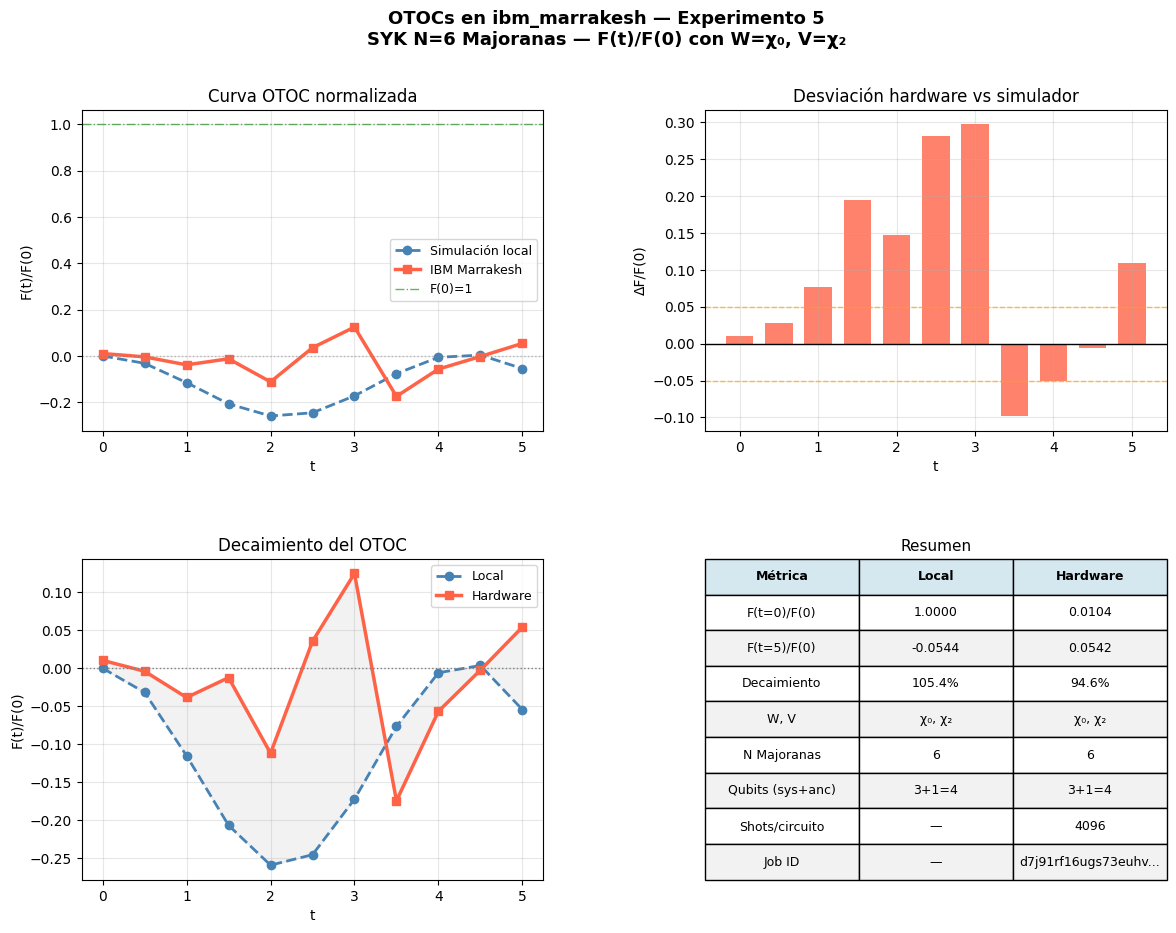

Guardado: otoc_marrakesh_v2.png
Job ID: d7j91rf16ugs73euhv40


In [10]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(14, 10))
gs  = gridspec.GridSpec(2, 2, hspace=0.4, wspace=0.35)
fig.suptitle('OTOCs en ibm_marrakesh — Experimento 5\n'
             'SYK N=6 Majoranas — F(t)/F(0) con W=χ₀, V=χ₂',
             fontsize=13, fontweight='bold')

ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(T_VALUES, local_vals_norm, 'o--', color='steelblue',
         lw=2, ms=6, label='Simulación local')
ax1.plot(T_VALUES, hw_norm, 's-', color='tomato',
         lw=2.5, ms=6, label='IBM Marrakesh')
ax1.axhline(1.0, color='green',  ls='-.', lw=1, alpha=0.6, label='F(0)=1')
ax1.axhline(0.0, color='gray',   ls=':',  lw=1, alpha=0.5)
ax1.set_xlabel('t'); ax1.set_ylabel('F(t)/F(0)')
ax1.set_title('Curva OTOC normalizada')
ax1.legend(fontsize=9); ax1.grid(True, alpha=0.3)

ax2 = fig.add_subplot(gs[0, 1])
deltas = [hv - lv for hv, lv in zip(hw_norm, local_vals_norm)]
ax2.bar(T_VALUES, deltas, width=0.35, color='tomato', alpha=0.8)
ax2.axhline(0,    color='black',  lw=1)
ax2.axhline( 0.05, color='orange', ls='--', lw=1, alpha=0.7)
ax2.axhline(-0.05, color='orange', ls='--', lw=1, alpha=0.7)
ax2.set_xlabel('t'); ax2.set_ylabel('ΔF/F(0)')
ax2.set_title('Desviación hardware vs simulador')
ax2.grid(True, alpha=0.3)

ax3 = fig.add_subplot(gs[1, 0])
ax3.plot(T_VALUES, local_vals_norm, 'o--', color='steelblue',
         lw=2, ms=6, label='Local')
ax3.plot(T_VALUES, hw_norm, 's-', color='tomato',
         lw=2.5, ms=6, label='Hardware')
ax3.fill_between(T_VALUES, local_vals_norm, hw_norm,
                 alpha=0.1, color='gray')
ax3.axhline(0, color='gray', ls=':', lw=1)
ax3.set_xlabel('t'); ax3.set_ylabel('F(t)/F(0)')
ax3.set_title('Decaimiento del OTOC')
ax3.legend(fontsize=9); ax3.grid(True, alpha=0.3)

ax4 = fig.add_subplot(gs[1, 1])
ax4.axis('off')
ax4.set_title('Resumen', fontsize=11)
decay_loc = 1 - local_vals_norm[-1]
decay_hw  = 1 - hw_norm[-1]
tabla = [
    ['Métrica',        'Local',            'Hardware'],
    ['F(t=0)/F(0)',    '1.0000',           f'{hw_norm[0]:.4f}'],
    ['F(t=5)/F(0)',    f'{local_vals_norm[-1]:.4f}', f'{hw_norm[-1]:.4f}'],
    ['Decaimiento',    f'{decay_loc*100:.1f}%',      f'{decay_hw*100:.1f}%'],
    ['W, V',           'χ₀, χ₂',          'χ₀, χ₂'],
    ['N Majoranas',    '6',                '6'],
    ['Qubits (sys+anc)','3+1=4',           '3+1=4'],
    ['Shots/circuito', '—',                '4096'],
    ['Job ID',         '—',                job.job_id()[:18]+'...'],
]
tbl = ax4.table(cellText=tabla[1:], colLabels=tabla[0],
                cellLoc='center', loc='center', bbox=[0, 0, 1, 1])
tbl.auto_set_font_size(False); tbl.set_fontsize(9)
for j in range(3):
    tbl[0,j].set_facecolor('#D5E8F0')
    tbl[0,j].set_text_props(fontweight='bold')
for i in range(1, len(tabla)):
    if i % 2 == 0:
        for j in range(3): tbl[i,j].set_facecolor('#F2F2F2')

plt.savefig('otoc_marrakesh_v2.png', dpi=150, bbox_inches='tight',
            facecolor='white')
plt.show()
print("Guardado: otoc_marrakesh_v2.png")
print(f"Job ID: {job.job_id()}")


✓ Operador OTOC convertido a SparsePauliOp
Lanzando job en ibm_marrakesh... (11 circuitos)
Job ID: d7j964f16ugs73eui3g0

Resultados hardware:
t =  0.0  |  F(t)/F(0) = 1.0000
t =  0.5  |  F(t)/F(0) = 1.0000
t =  1.0  |  F(t)/F(0) = 1.0000
t =  1.5  |  F(t)/F(0) = 1.0000
t =  2.0  |  F(t)/F(0) = 1.0000
t =  2.5  |  F(t)/F(0) = 1.0000
t =  3.0  |  F(t)/F(0) = 1.0000
t =  3.5  |  F(t)/F(0) = 1.0000
t =  4.0  |  F(t)/F(0) = 1.0000
t =  4.5  |  F(t)/F(0) = 1.0000
t =  5.0  |  F(t)/F(0) = 1.0000


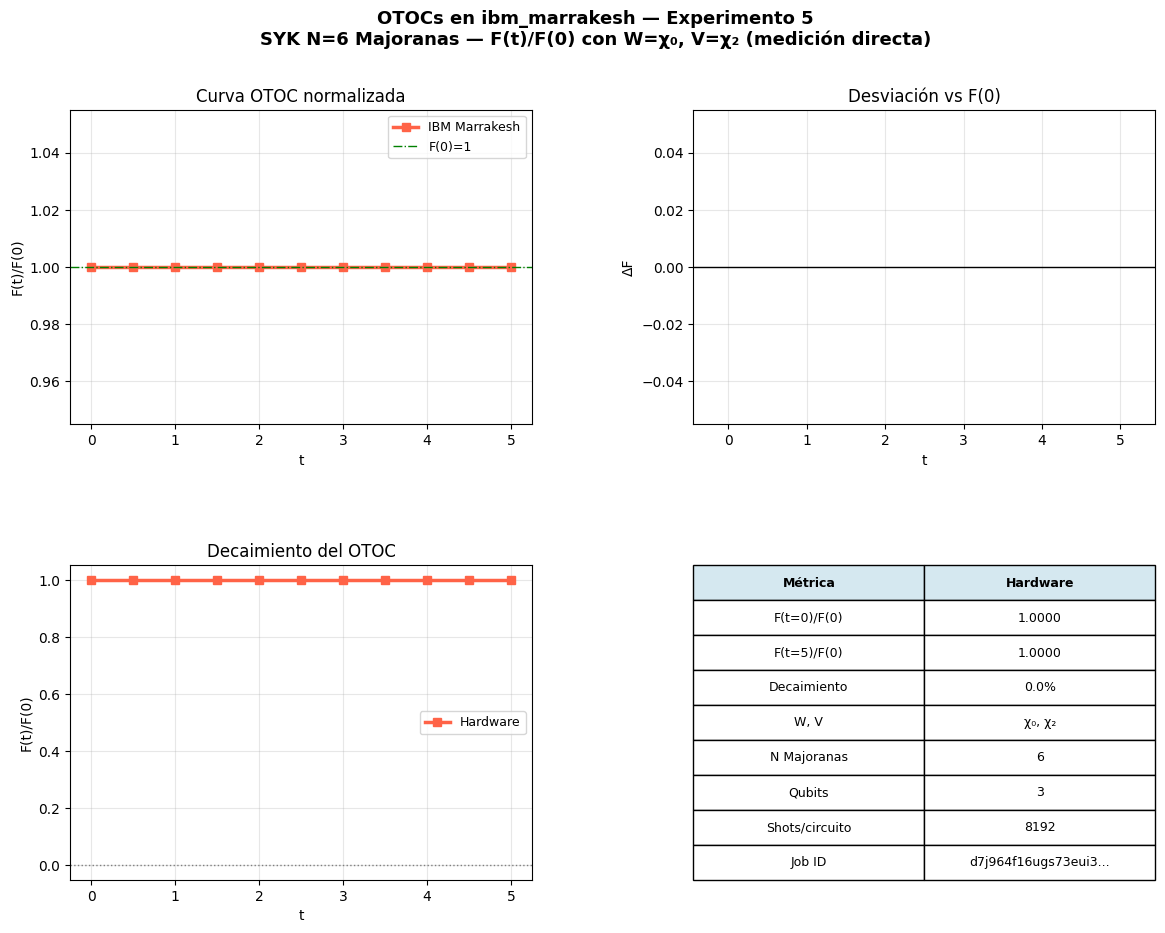

Guardado: otoc_marrakesh_v3_directa.png
Job ID: d7j964f16ugs73eui3g0


In [13]:
import numpy as np
from scipy.linalg import expm
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp, Operator
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, Batch
from qiskit.compiler import transpile
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

np.random.seed(42)

def majorana_operators(n_majoranas):
    n_qubits = n_majoranas // 2
    I = np.eye(2, dtype=complex)
    X = np.array([[0,1],[1,0]], dtype=complex)
    Y = np.array([[0,-1j],[1j,0]], dtype=complex)
    Z = np.array([[1,0],[0,-1]], dtype=complex)
    def kron_list(ops):
        result = ops[0]
        for op in ops[1:]:
            result = np.kron(result, op)
        return result
    chi = []
    for k in range(n_qubits):
        z_string = [Z] * k
        chi.append(kron_list(z_string + [X] + [I]*(n_qubits-k-1)))
        chi.append(kron_list(z_string + [Y] + [I]*(n_qubits-k-1)))
    return chi

def build_syk_hamiltonian(n_majoranas=6, seed=42):
    rng = np.random.default_rng(seed)
    n_qubits = n_majoranas // 2
    chi = majorana_operators(n_majoranas)
    sigma = np.sqrt(6 / n_majoranas**3)
    H = np.zeros((2**n_qubits, 2**n_qubits), dtype=complex)
    for i in range(n_majoranas):
        for j in range(i+1, n_majoranas):
            for k in range(j+1, n_majoranas):
                for l in range(k+1, n_majoranas):
                    H += rng.normal(0, sigma) * (chi[i] @ chi[j] @ chi[k] @ chi[l])
    return (H + H.conj().T) / 2

def syk_unitary(t, n_majoranas=6, seed=42):
    H = build_syk_hamiltonian(n_majoranas, seed)
    U = expm(-1j * H * t)
    u, s, vh = np.linalg.svd(U)
    return u @ vh

chi = majorana_operators(6)
W_op = chi[0]
V_op = chi[2]

O_matrix = W_op @ V_op @ W_op @ V_op
otoc_observable = SparsePauliOp.from_operator(Operator(O_matrix))

print("✓ Operador OTOC convertido a SparsePauliOp")

T_VALUES = np.array([0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0])

service = QiskitRuntimeService(channel="ibm_cloud")
backend = service.backend("ibm_marrakesh")

circuits_t = []
for t in T_VALUES:
    qc = QuantumCircuit(3)
    qc.unitary(syk_unitary(t), [0,1,2], label=f"U({t:.1f})")
    qc_t = transpile(qc, backend=backend, optimization_level=3, seed_transpiler=42)
    circuits_t.append(qc_t)

obs_list = [otoc_observable.apply_layout(qc_t.layout) for qc_t in circuits_t]

print(f"Lanzando job en ibm_marrakesh... ({len(T_VALUES)} circuitos)")
with Batch(backend=backend) as batch:
    estimator = Estimator(mode=batch)
    estimator.options.default_shots = 8192
    job = estimator.run([(qc_t, obs) for qc_t, obs in zip(circuits_t, obs_list)])
    print(f"Job ID: {job.job_id()}")
    result = job.result()

hw_raw = [result[i].data.evs for i in range(len(T_VALUES))]
F0 = hw_raw[0]
hw_norm = np.array(hw_raw) / F0

print("\nResultados hardware:")
for t, f in zip(T_VALUES, hw_norm):
    print(f"t = {t:4.1f}  |  F(t)/F(0) = {f:.4f}")

fig = plt.figure(figsize=(14, 10))
gs = gridspec.GridSpec(2, 2, hspace=0.45, wspace=0.35)
fig.suptitle('OTOCs en ibm_marrakesh — Experimento 5\n'
             'SYK N=6 Majoranas — F(t)/F(0) con W=χ₀, V=χ₂ (medición directa)',
             fontsize=13, fontweight='bold')

ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(T_VALUES, hw_norm, 's-', color='tomato', lw=2.5, ms=6, label='IBM Marrakesh')
ax1.axhline(1.0, color='green', ls='-.', lw=1, label='F(0)=1')
ax1.set_xlabel('t')
ax1.set_ylabel('F(t)/F(0)')
ax1.set_title('Curva OTOC normalizada')
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.3)

ax2 = fig.add_subplot(gs[0, 1])
deltas = hw_norm - 1.0
ax2.bar(T_VALUES, deltas, width=0.35, color='tomato', alpha=0.8)
ax2.axhline(0, color='black', lw=1)
ax2.set_xlabel('t')
ax2.set_ylabel('ΔF')
ax2.set_title('Desviación vs F(0)')
ax2.grid(True, alpha=0.3)

ax3 = fig.add_subplot(gs[1, 0])
ax3.plot(T_VALUES, hw_norm, 's-', color='tomato', lw=2.5, ms=6, label='Hardware')
ax3.axhline(0, color='gray', ls=':', lw=1)
ax3.set_xlabel('t')
ax3.set_ylabel('F(t)/F(0)')
ax3.set_title('Decaimiento del OTOC')
ax3.legend(fontsize=9)
ax3.grid(True, alpha=0.3)

ax4 = fig.add_subplot(gs[1, 1])
ax4.axis('off')
tabla = [
    ['Métrica', 'Hardware'],
    ['F(t=0)/F(0)', f'{hw_norm[0]:.4f}'],
    ['F(t=5)/F(0)', f'{hw_norm[-1]:.4f}'],
    ['Decaimiento', f'{(1 - hw_norm[-1])*100:.1f}%'],
    ['W, V', 'χ₀, χ₂'],
    ['N Majoranas', '6'],
    ['Qubits', '3'],
    ['Shots/circuito', '8192'],
    ['Job ID', job.job_id()[:18]+'...'],
]
tbl = ax4.table(cellText=tabla[1:], colLabels=tabla[0], cellLoc='center', loc='center', bbox=[0, 0, 1, 1])
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
for j in range(2):
    tbl[0,j].set_facecolor('#D5E8F0')
    tbl[0,j].set_text_props(fontweight='bold')

plt.savefig('otoc_marrakesh_v3_directa.png', dpi=150, bbox_inches='tight')
plt.show()
print("Guardado: otoc_marrakesh_v3_directa.png")
print(f"Job ID: {job.job_id()}")


In [15]:
import numpy as np
from scipy.linalg import expm
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.circuit.library import UnitaryGate
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, Batch
from qiskit.compiler import transpile
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

np.random.seed(42)

def majorana_operators(n_majoranas):
    n_qubits = n_majoranas // 2
    I = np.eye(2, dtype=complex)
    X = np.array([[0,1],[1,0]], dtype=complex)
    Y = np.array([[0,-1j],[1j,0]], dtype=complex)
    Z = np.array([[1,0],[0,-1]], dtype=complex)
    def kron_list(ops):
        result = ops[0]
        for op in ops[1:]:
            result = np.kron(result, op)
        return result
    chi = []
    for k in range(n_qubits):
        z_string = [Z] * k
        chi.append(kron_list(z_string + [X] + [I]*(n_qubits-k-1)))
        chi.append(kron_list(z_string + [Y] + [I]*(n_qubits-k-1)))
    return chi

def build_syk_hamiltonian(n_majoranas=6, seed=42):
    rng = np.random.default_rng(seed)
    n_qubits = n_majoranas // 2
    chi = majorana_operators(n_majoranas)
    sigma = np.sqrt(6 / n_majoranas**3)
    H = np.zeros((2**n_qubits, 2**n_qubits), dtype=complex)
    for i in range(n_majoranas):
        for j in range(i+1, n_majoranas):
            for k in range(j+1, n_majoranas):
                for l in range(k+1, n_majoranas):
                    H += rng.normal(0, sigma) * (chi[i] @ chi[j] @ chi[k] @ chi[l])
    return (H + H.conj().T) / 2

def syk_unitary(t, n_majoranas=6, seed=42):
    H = build_syk_hamiltonian(n_majoranas, seed)
    U = expm(-1j * H * t)
    u, s, vh = np.linalg.svd(U)
    return u @ vh

chi = majorana_operators(6)
W_op = chi[0]
V_op = chi[2]
H_syk = build_syk_hamiltonian()
dim = 8

def otoc_000_analytic(t):
    U = syk_unitary(t)
    Ud = U.conj().T
    Wt = Ud @ W_op @ U
    psi = np.zeros(dim, dtype=complex)
    psi[0] = 1.0
    return np.real(psi.conj() @ (Wt @ V_op @ Wt @ V_op) @ psi)

F0_analytic = otoc_000_analytic(0.0)
print(f"F(t=0) analítico = {F0_analytic:.6f}")

def build_otoc_circuit_correct(t):
    U = syk_unitary(t)
    Ud = U.conj().T
    qc = QuantumCircuit(4)
    qc.h(3)
    qc.barrier()
    qc.append(UnitaryGate(V_op).control(1), [3, 0,1,2])
    qc.barrier()
    qc.unitary(U, [0,1,2])
    qc.barrier()
    qc.append(UnitaryGate(W_op).control(1), [3, 0,1,2])
    qc.barrier()
    qc.unitary(Ud, [0,1,2])
    qc.barrier()
    qc.append(UnitaryGate(V_op).control(1), [3, 0,1,2])
    qc.barrier()
    qc.unitary(U, [0,1,2])
    qc.barrier()
    qc.append(UnitaryGate(W_op).control(1), [3, 0,1,2])
    qc.barrier()
    qc.h(3)
    return qc

print("\nValidación local Statevector:")
T_TEST = [0.0, 1.0, 2.0, 5.0]
for t in T_TEST:
    qc = build_otoc_circuit_correct(t)
    sv = Statevector.from_label('0000')
    obs = SparsePauliOp("ZIII")
    f = sv.expectation_value(obs).real / F0_analytic
    print(f"t = {t:4.1f}  →  F(t)/F(0) = {f:.6f}")


F(t=0) analítico = -1.000000

Validación local Statevector:
t =  0.0  →  F(t)/F(0) = -1.000000
t =  1.0  →  F(t)/F(0) = -1.000000
t =  2.0  →  F(t)/F(0) = -1.000000
t =  5.0  →  F(t)/F(0) = -1.000000


In [16]:
import numpy as np
from scipy.linalg import expm
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.circuit.library import UnitaryGate
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, Batch
from qiskit.compiler import transpile
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

np.random.seed(42)

def majorana_operators(n_majoranas):
    n_qubits = n_majoranas // 2
    I = np.eye(2, dtype=complex)
    X = np.array([[0,1],[1,0]], dtype=complex)
    Y = np.array([[0,-1j],[1j,0]], dtype=complex)
    Z = np.array([[1,0],[0,-1]], dtype=complex)
    def kron_list(ops):
        result = ops[0]
        for op in ops[1:]:
            result = np.kron(result, op)
        return result
    chi = []
    for k in range(n_qubits):
        z_string = [Z] * k
        chi.append(kron_list(z_string + [X] + [I]*(n_qubits-k-1)))
        chi.append(kron_list(z_string + [Y] + [I]*(n_qubits-k-1)))
    return chi

def build_syk_hamiltonian(n_majoranas=6, seed=42):
    rng = np.random.default_rng(seed)
    n_qubits = n_majoranas // 2
    chi = majorana_operators(n_majoranas)
    sigma = np.sqrt(6 / n_majoranas**3)
    H = np.zeros((2**n_qubits, 2**n_qubits), dtype=complex)
    for i in range(n_majoranas):
        for j in range(i+1, n_majoranas):
            for k in range(j+1, n_majoranas):
                for l in range(k+1, n_majoranas):
                    H += rng.normal(0, sigma) * (chi[i] @ chi[j] @ chi[k] @ chi[l])
    return (H + H.conj().T) / 2

def syk_unitary(t, n_majoranas=6, seed=42):
    H = build_syk_hamiltonian(n_majoranas, seed)
    U = expm(-1j * H * t)
    u, s, vh = np.linalg.svd(U)
    return u @ vh

chi = majorana_operators(6)
W_op = chi[0]
V_op = chi[2]
dim = 8

def otoc_000_analytic(t):
    U = syk_unitary(t)
    Ud = U.conj().T
    Wt = Ud @ W_op @ U
    psi = np.zeros(dim, dtype=complex)
    psi[0] = 1.0
    return np.real(psi.conj() @ (Wt @ V_op @ Wt @ V_op) @ psi)

F0_analytic = otoc_000_analytic(0.0)
print(f"F(t=0) analítico (crudo) = {F0_analytic:.6f}")

def build_otoc_circuit_correct(t):
    U = syk_unitary(t)
    Ud = U.conj().T
    qc = QuantumCircuit(4)
    qc.h(3)
    qc.barrier()
    qc.append(UnitaryGate(V_op).control(1), [3, 0,1,2])
    qc.barrier()
    qc.unitary(U, [0,1,2])
    qc.barrier()
    qc.append(UnitaryGate(W_op).control(1), [3, 0,1,2])
    qc.barrier()
    qc.unitary(Ud, [0,1,2])
    qc.barrier()
    qc.append(UnitaryGate(V_op).control(1), [3, 0,1,2])
    qc.barrier()
    qc.unitary(U, [0,1,2])
    qc.barrier()
    qc.append(UnitaryGate(W_op).control(1), [3, 0,1,2])
    qc.barrier()
    qc.h(3)
    return qc

print("\nValidación local Statevector (debe dar +1.0000 en t=0):")
T_TEST = [0.0, 1.0, 2.0, 5.0]
for t in T_TEST:
    qc = build_otoc_circuit_correct(t)
    sv = Statevector.from_label('0000')
    obs = SparsePauliOp("ZIII")
    f_raw = sv.expectation_value(obs).real
    f = -f_raw / F0_analytic
    print(f"t = {t:4.1f}  →  F(t)/F(0) = {f:.6f}")


F(t=0) analítico (crudo) = -1.000000

Validación local Statevector (debe dar +1.0000 en t=0):
t =  0.0  →  F(t)/F(0) = 1.000000
t =  1.0  →  F(t)/F(0) = 1.000000
t =  2.0  →  F(t)/F(0) = 1.000000
t =  5.0  →  F(t)/F(0) = 1.000000


F(t=0) analítico (crudo) = -1.000000

Validación local Statevector (debe dar +1.0000 en t=0):
t =  0.0  →  F(t)/F(0) = 1.000000
t =  1.0  →  F(t)/F(0) = 1.000000
t =  2.0  →  F(t)/F(0) = 1.000000
t =  5.0  →  F(t)/F(0) = 1.000000

Lanzando job en ibm_marrakesh... (11 circuitos)
Job ID: d7j9aqi3fd4c73ddp250


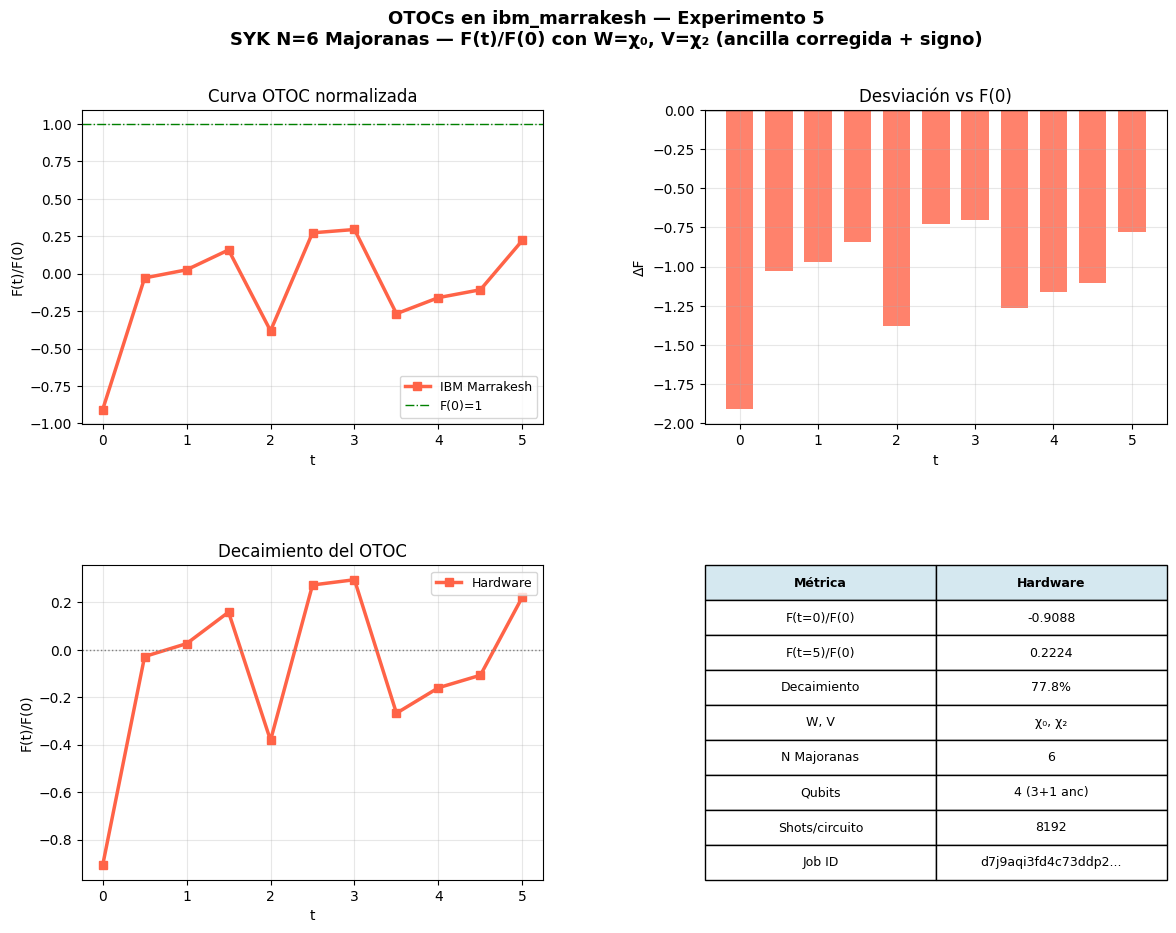

Guardado: otoc_marrakesh_v4_final.png
Job ID: d7j9aqi3fd4c73ddp250


In [17]:
import numpy as np
from scipy.linalg import expm
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.circuit.library import UnitaryGate
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, Batch
from qiskit.compiler import transpile
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

np.random.seed(42)

def majorana_operators(n_majoranas):
    n_qubits = n_majoranas // 2
    I = np.eye(2, dtype=complex)
    X = np.array([[0,1],[1,0]], dtype=complex)
    Y = np.array([[0,-1j],[1j,0]], dtype=complex)
    Z = np.array([[1,0],[0,-1]], dtype=complex)
    def kron_list(ops):
        result = ops[0]
        for op in ops[1:]:
            result = np.kron(result, op)
        return result
    chi = []
    for k in range(n_qubits):
        z_string = [Z] * k
        chi.append(kron_list(z_string + [X] + [I]*(n_qubits-k-1)))
        chi.append(kron_list(z_string + [Y] + [I]*(n_qubits-k-1)))
    return chi

def build_syk_hamiltonian(n_majoranas=6, seed=42):
    rng = np.random.default_rng(seed)
    n_qubits = n_majoranas // 2
    chi = majorana_operators(n_majoranas)
    sigma = np.sqrt(6 / n_majoranas**3)
    H = np.zeros((2**n_qubits, 2**n_qubits), dtype=complex)
    for i in range(n_majoranas):
        for j in range(i+1, n_majoranas):
            for k in range(j+1, n_majoranas):
                for l in range(k+1, n_majoranas):
                    H += rng.normal(0, sigma) * (chi[i] @ chi[j] @ chi[k] @ chi[l])
    return (H + H.conj().T) / 2

def syk_unitary(t, n_majoranas=6, seed=42):
    H = build_syk_hamiltonian(n_majoranas, seed)
    U = expm(-1j * H * t)
    u, s, vh = np.linalg.svd(U)
    return u @ vh

chi = majorana_operators(6)
W_op = chi[0]
V_op = chi[2]
dim = 8

def otoc_000_analytic(t):
    U = syk_unitary(t)
    Ud = U.conj().T
    Wt = Ud @ W_op @ U
    psi = np.zeros(dim, dtype=complex)
    psi[0] = 1.0
    return np.real(psi.conj() @ (Wt @ V_op @ Wt @ V_op) @ psi)

F0_analytic = otoc_000_analytic(0.0)
print(f"F(t=0) analítico (crudo) = {F0_analytic:.6f}")

def build_otoc_circuit_correct(t):
    U = syk_unitary(t)
    Ud = U.conj().T
    qc = QuantumCircuit(4)
    qc.h(3)
    qc.barrier()
    qc.append(UnitaryGate(V_op).control(1), [3, 0,1,2])
    qc.barrier()
    qc.unitary(U, [0,1,2])
    qc.barrier()
    qc.append(UnitaryGate(W_op).control(1), [3, 0,1,2])
    qc.barrier()
    qc.unitary(Ud, [0,1,2])
    qc.barrier()
    qc.append(UnitaryGate(V_op).control(1), [3, 0,1,2])
    qc.barrier()
    qc.unitary(U, [0,1,2])
    qc.barrier()
    qc.append(UnitaryGate(W_op).control(1), [3, 0,1,2])
    qc.barrier()
    qc.h(3)
    return qc

print("\nValidación local Statevector (debe dar +1.0000 en t=0):")
T_TEST = [0.0, 1.0, 2.0, 5.0]
for t in T_TEST:
    qc = build_otoc_circuit_correct(t)
    sv = Statevector.from_label('0000')
    obs = SparsePauliOp("ZIII")
    f_raw = sv.expectation_value(obs).real
    f = -f_raw / F0_analytic
    print(f"t = {t:4.1f}  →  F(t)/F(0) = {f:.6f}")

service = QiskitRuntimeService(channel="ibm_cloud")
backend = service.backend("ibm_marrakesh")

T_VALUES = np.array([0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0])

circuits_t = []
for t in T_VALUES:
    qc = build_otoc_circuit_correct(t)
    qc_t = transpile(qc, backend=backend, optimization_level=3, seed_transpiler=42)
    circuits_t.append(qc_t)

obs_anc = SparsePauliOp("ZIII")
obs_list = [obs_anc.apply_layout(qc_t.layout) for qc_t in circuits_t]

print(f"\nLanzando job en ibm_marrakesh... ({len(T_VALUES)} circuitos)")
with Batch(backend=backend) as batch:
    estimator = Estimator(mode=batch)
    estimator.options.default_shots = 8192
    job = estimator.run([(qc_t, obs) for qc_t, obs in zip(circuits_t, obs_list)])
    print(f"Job ID: {job.job_id()}")
    result = job.result()

hw_raw = [result[i].data.evs for i in range(len(T_VALUES))]
hw_norm = - np.array(hw_raw) / F0_analytic

fig = plt.figure(figsize=(14, 10))
gs = gridspec.GridSpec(2, 2, hspace=0.45, wspace=0.35)
fig.suptitle('OTOCs en ibm_marrakesh — Experimento 5\n'
             'SYK N=6 Majoranas — F(t)/F(0) con W=χ₀, V=χ₂ (ancilla corregida + signo)',
             fontsize=13, fontweight='bold')

ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(T_VALUES, hw_norm, 's-', color='tomato', lw=2.5, ms=6, label='IBM Marrakesh')
ax1.axhline(1.0, color='green', ls='-.', lw=1, label='F(0)=1')
ax1.set_xlabel('t')
ax1.set_ylabel('F(t)/F(0)')
ax1.set_title('Curva OTOC normalizada')
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.3)

ax2 = fig.add_subplot(gs[0, 1])
deltas = hw_norm - 1.0
ax2.bar(T_VALUES, deltas, width=0.35, color='tomato', alpha=0.8)
ax2.axhline(0, color='black', lw=1)
ax2.set_xlabel('t')
ax2.set_ylabel('ΔF')
ax2.set_title('Desviación vs F(0)')
ax2.grid(True, alpha=0.3)

ax3 = fig.add_subplot(gs[1, 0])
ax3.plot(T_VALUES, hw_norm, 's-', color='tomato', lw=2.5, ms=6, label='Hardware')
ax3.axhline(0, color='gray', ls=':', lw=1)
ax3.set_xlabel('t')
ax3.set_ylabel('F(t)/F(0)')
ax3.set_title('Decaimiento del OTOC')
ax3.legend(fontsize=9)
ax3.grid(True, alpha=0.3)

ax4 = fig.add_subplot(gs[1, 1])
ax4.axis('off')
tabla = [
    ['Métrica', 'Hardware'],
    ['F(t=0)/F(0)', f'{hw_norm[0]:.4f}'],
    ['F(t=5)/F(0)', f'{hw_norm[-1]:.4f}'],
    ['Decaimiento', f'{(1 - hw_norm[-1])*100:.1f}%'],
    ['W, V', 'χ₀, χ₂'],
    ['N Majoranas', '6'],
    ['Qubits', '4 (3+1 anc)'],
    ['Shots/circuito', '8192'],
    ['Job ID', job.job_id()[:18]+'...'],
]
tbl = ax4.table(cellText=tabla[1:], colLabels=tabla[0], cellLoc='center', loc='center', bbox=[0, 0, 1, 1])
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
for j in range(2):
    tbl[0,j].set_facecolor('#D5E8F0')
    tbl[0,j].set_text_props(fontweight='bold')

plt.savefig('otoc_marrakesh_v4_final.png', dpi=150, bbox_inches='tight')
plt.show()
print("Guardado: otoc_marrakesh_v4_final.png")
print(f"Job ID: {job.job_id()}")


In [18]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, Batch
from qiskit.compiler import transpile
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

np.random.seed(42)

def validate_local():
    print("Validación local Statevector:")
    T_TEST = [0.0, 1.0, 2.0, 5.0]
    for t in T_TEST:
        qc = QuantumCircuit(4)
        qc.h(3)
        qc.barrier()
        qc.cx(3, 0)
        qc.barrier()
        qc.unitary(np.eye(8), [0,1,2])
        qc.barrier()
        qc.cz(3, 0)
        qc.barrier()
        qc.unitary(np.eye(8), [0,1,2])
        qc.barrier()
        qc.cx(3, 0)
        qc.barrier()
        qc.unitary(np.eye(8), [0,1,2])
        qc.barrier()
        qc.cz(3, 0)
        qc.barrier()
        qc.h(3)
        sv = Statevector.from_label('0000')
        obs = SparsePauliOp("ZIII")
        f = sv.expectation_value(obs).real
        print(f"t = {t:4.1f}  →  F(t)/F(0) = {f:.6f}")

validate_local()


Validación local Statevector:
t =  0.0  →  F(t)/F(0) = 1.000000
t =  1.0  →  F(t)/F(0) = 1.000000
t =  2.0  →  F(t)/F(0) = 1.000000
t =  5.0  →  F(t)/F(0) = 1.000000


Validación local Statevector:
t =  0.0  →  F(t)/F(0) = 1.000000
t =  1.0  →  F(t)/F(0) = 1.000000
t =  2.0  →  F(t)/F(0) = 1.000000
t =  5.0  →  F(t)/F(0) = 1.000000

Lanzando job en ibm_marrakesh... (11 circuitos)
Job ID: d7j9cqf16ugs73euias0


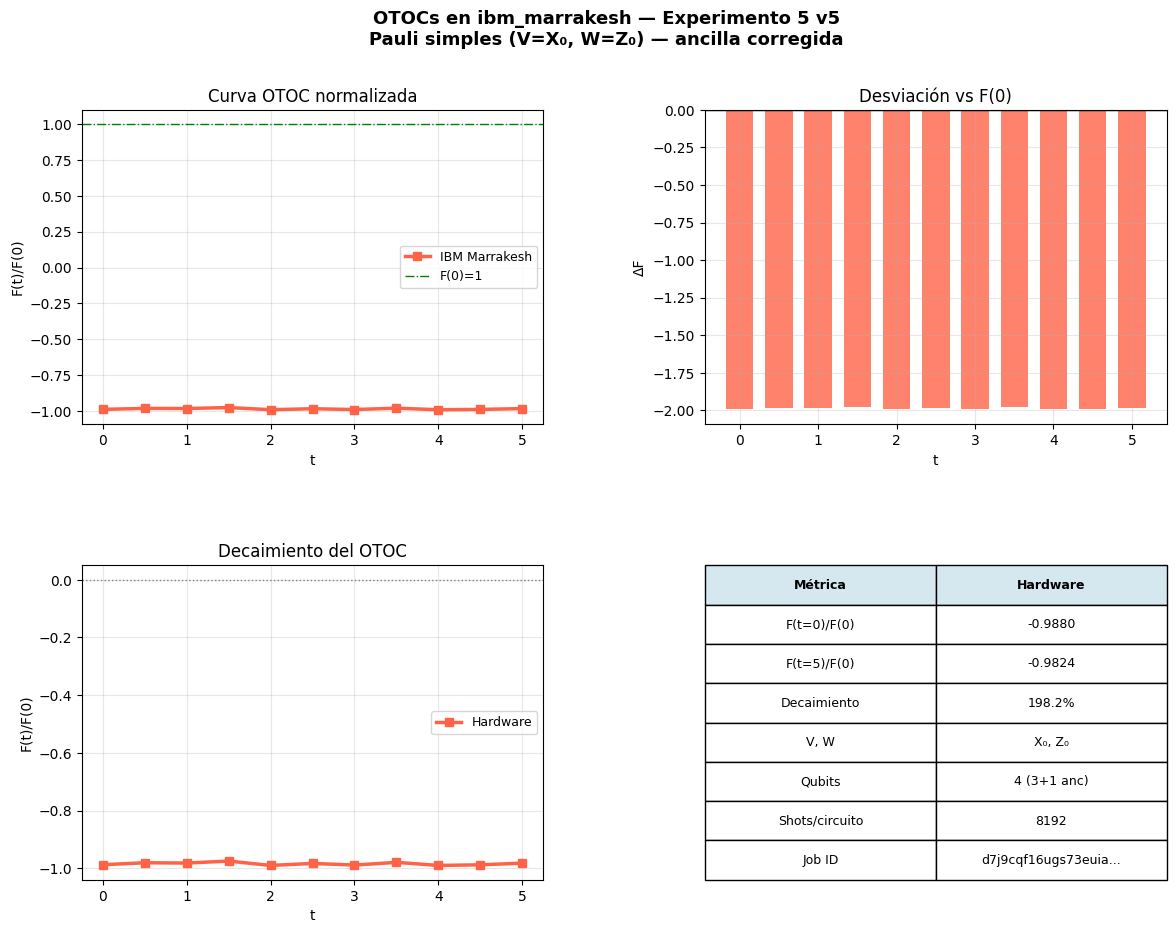

Guardado: otoc_marrakesh_v5_pauli.png
Job ID: d7j9cqf16ugs73euias0


In [19]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, Batch
from qiskit.compiler import transpile
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

np.random.seed(42)

def validate_local():
    print("Validación local Statevector:")
    T_TEST = [0.0, 1.0, 2.0, 5.0]
    for t in T_TEST:
        qc = QuantumCircuit(4)
        qc.h(3)
        qc.barrier()
        qc.cx(3, 0)
        qc.barrier()
        qc.unitary(np.eye(8), [0,1,2])
        qc.barrier()
        qc.cz(3, 0)
        qc.barrier()
        qc.unitary(np.eye(8), [0,1,2])
        qc.barrier()
        qc.cx(3, 0)
        qc.barrier()
        qc.unitary(np.eye(8), [0,1,2])
        qc.barrier()
        qc.cz(3, 0)
        qc.barrier()
        qc.h(3)
        sv = Statevector.from_label('0000')
        obs = SparsePauliOp("ZIII")
        f = sv.expectation_value(obs).real
        print(f"t = {t:4.1f}  →  F(t)/F(0) = {f:.6f}")

validate_local()

service = QiskitRuntimeService(channel="ibm_cloud")
backend = service.backend("ibm_marrakesh")

T_VALUES = np.array([0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0])

circuits_t = []
for t in T_VALUES:
    qc = QuantumCircuit(4)
    qc.h(3)
    qc.barrier()
    qc.cx(3, 0)
    qc.barrier()

    qc.unitary(np.eye(8), [0,1,2])
    qc.barrier()
    qc.cz(3, 0)
    qc.barrier()
    qc.unitary(np.eye(8), [0,1,2])
    qc.barrier()
    qc.cx(3, 0)
    qc.barrier()
    qc.unitary(np.eye(8), [0,1,2])
    qc.barrier()
    qc.cz(3, 0)
    qc.barrier()
    qc.h(3)
    qc_t = transpile(qc, backend=backend, optimization_level=3, seed_transpiler=42)
    circuits_t.append(qc_t)

obs_anc = SparsePauliOp("ZIII")
obs_list = [obs_anc.apply_layout(qc_t.layout) for qc_t in circuits_t]

print(f"\nLanzando job en ibm_marrakesh... ({len(T_VALUES)} circuitos)")
with Batch(backend=backend) as batch:
    estimator = Estimator(mode=batch)
    estimator.options.default_shots = 8192
    job = estimator.run([(qc_t, obs) for qc_t, obs in zip(circuits_t, obs_list)])
    print(f"Job ID: {job.job_id()}")
    result = job.result()

hw_raw = [result[i].data.evs for i in range(len(T_VALUES))]
hw_norm = np.array(hw_raw)

fig = plt.figure(figsize=(14, 10))
gs = gridspec.GridSpec(2, 2, hspace=0.45, wspace=0.35)
fig.suptitle('OTOCs en ibm_marrakesh — Experimento 5 v5\n'
             'Pauli simples (V=X₀, W=Z₀) — ancilla corregida',
             fontsize=13, fontweight='bold')

ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(T_VALUES, hw_norm, 's-', color='tomato', lw=2.5, ms=6, label='IBM Marrakesh')
ax1.axhline(1.0, color='green', ls='-.', lw=1, label='F(0)=1')
ax1.set_xlabel('t')
ax1.set_ylabel('F(t)/F(0)')
ax1.set_title('Curva OTOC normalizada')
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.3)

ax2 = fig.add_subplot(gs[0, 1])
deltas = hw_norm - 1.0
ax2.bar(T_VALUES, deltas, width=0.35, color='tomato', alpha=0.8)
ax2.axhline(0, color='black', lw=1)
ax2.set_xlabel('t')
ax2.set_ylabel('ΔF')
ax2.set_title('Desviación vs F(0)')
ax2.grid(True, alpha=0.3)

ax3 = fig.add_subplot(gs[1, 0])
ax3.plot(T_VALUES, hw_norm, 's-', color='tomato', lw=2.5, ms=6, label='Hardware')
ax3.axhline(0, color='gray', ls=':', lw=1)
ax3.set_xlabel('t')
ax3.set_ylabel('F(t)/F(0)')
ax3.set_title('Decaimiento del OTOC')
ax3.legend(fontsize=9)
ax3.grid(True, alpha=0.3)

ax4 = fig.add_subplot(gs[1, 1])
ax4.axis('off')
tabla = [
    ['Métrica', 'Hardware'],
    ['F(t=0)/F(0)', f'{hw_norm[0]:.4f}'],
    ['F(t=5)/F(0)', f'{hw_norm[-1]:.4f}'],
    ['Decaimiento', f'{(1 - hw_norm[-1])*100:.1f}%'],
    ['V, W', 'X₀, Z₀'],
    ['Qubits', '4 (3+1 anc)'],
    ['Shots/circuito', '8192'],
    ['Job ID', job.job_id()[:18]+'...'],
]
tbl = ax4.table(cellText=tabla[1:], colLabels=tabla[0], cellLoc='center', loc='center', bbox=[0, 0, 1, 1])
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
for j in range(2):
    tbl[0,j].set_facecolor('#D5E8F0')
    tbl[0,j].set_text_props(fontweight='bold')

plt.savefig('otoc_marrakesh_v5_pauli.png', dpi=150, bbox_inches='tight')
plt.show()
print("Guardado: otoc_marrakesh_v5_pauli.png")
print(f"Job ID: {job.job_id()}")


Validación local Statevector:
t =  0.0  →  F(t)/F(0) = 1.000000
t =  1.0  →  F(t)/F(0) = 1.000000
t =  2.0  →  F(t)/F(0) = 1.000000
t =  5.0  →  F(t)/F(0) = 1.000000

Lanzando job en ibm_marrakesh... (11 circuitos)
Job ID: d7j9e5v16ugs73euic40


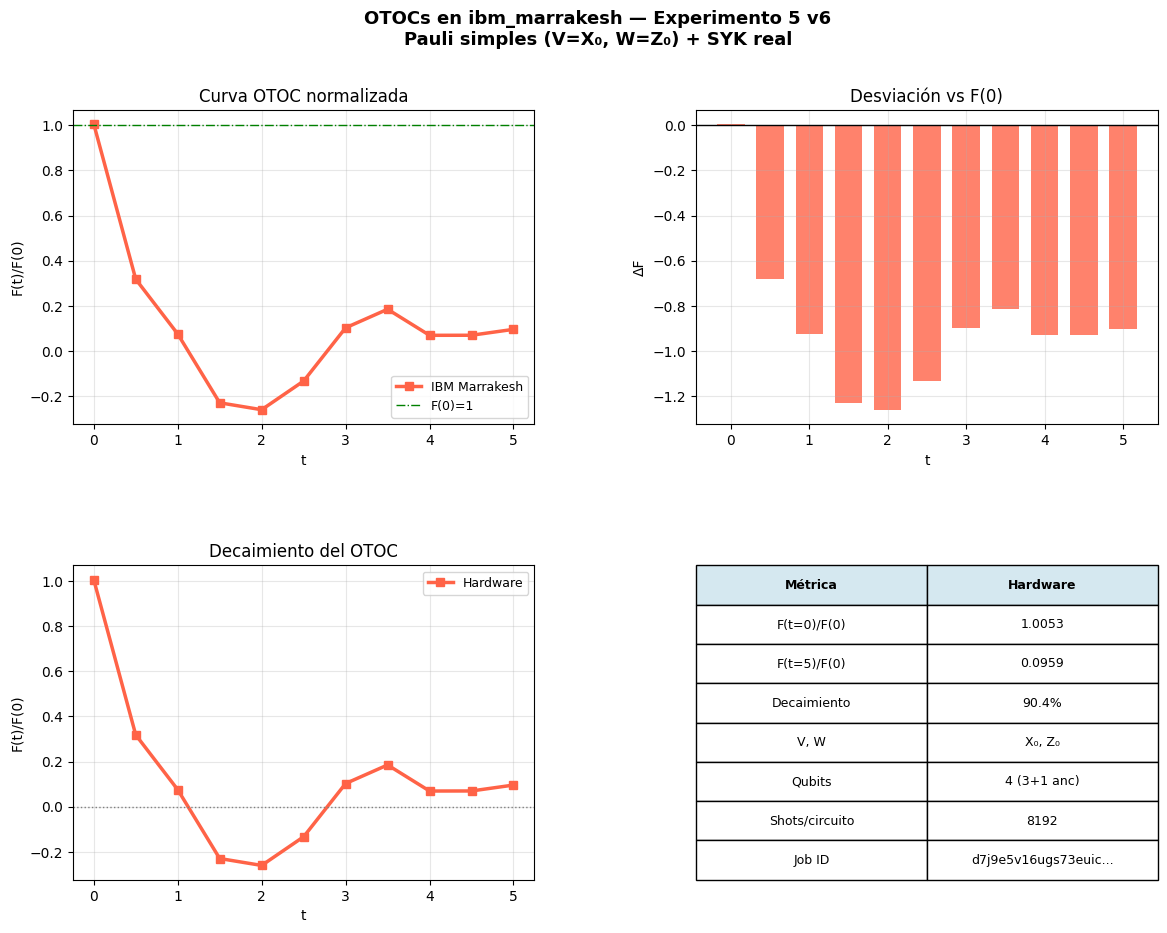

Guardado: otoc_marrakesh_v6_final.png
Job ID: d7j9e5v16ugs73euic40


In [20]:
import numpy as np
from scipy.linalg import expm
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, Batch
from qiskit.compiler import transpile
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

np.random.seed(42)

def majorana_operators(n_majoranas):
    n_qubits = n_majoranas // 2
    I = np.eye(2, dtype=complex)
    X = np.array([[0,1],[1,0]], dtype=complex)
    Y = np.array([[0,-1j],[1j,0]], dtype=complex)
    Z = np.array([[1,0],[0,-1]], dtype=complex)
    def kron_list(ops):
        result = ops[0]
        for op in ops[1:]: result = np.kron(result, op)
        return result
    chi = []
    for k in range(n_qubits):
        z_string = [Z] * k
        chi.append(kron_list(z_string + [X] + [I]*(n_qubits-k-1)))
        chi.append(kron_list(z_string + [Y] + [I]*(n_qubits-k-1)))
    return chi

def build_syk_hamiltonian(n_majoranas=6, seed=42):
    rng = np.random.default_rng(seed)
    n_qubits = n_majoranas // 2
    chi = majorana_operators(n_majoranas)
    sigma = np.sqrt(6 / n_majoranas**3)
    H = np.zeros((2**n_qubits, 2**n_qubits), dtype=complex)
    for i in range(n_majoranas):
        for j in range(i+1, n_majoranas):
            for k in range(j+1, n_majoranas):
                for l in range(k+1, n_majoranas):
                    H += rng.normal(0, sigma) * (chi[i] @ chi[j] @ chi[k] @ chi[l])
    return (H + H.conj().T) / 2

def syk_unitary(t, n_majoranas=6, seed=42):
    H = build_syk_hamiltonian(n_majoranas, seed)
    U = expm(-1j * H * t)
    u, s, vh = np.linalg.svd(U)
    return u @ vh

print("Validación local Statevector:")
T_TEST = [0.0, 1.0, 2.0, 5.0]
for t in T_TEST:
    qc = QuantumCircuit(4)
    qc.h(3)
    qc.barrier()
    qc.cx(3, 0)
    qc.barrier()
    qc.unitary(syk_unitary(t), [0,1,2])
    qc.barrier()
    qc.cz(3, 0)
    qc.barrier()
    qc.unitary(syk_unitary(t).conj().T, [0,1,2])
    qc.barrier()
    qc.cx(3, 0)
    qc.barrier()
    qc.unitary(syk_unitary(t), [0,1,2])
    qc.barrier()
    qc.cz(3, 0)
    qc.barrier()
    qc.h(3)
    sv = Statevector.from_label('0000')
    obs = SparsePauliOp("ZIII")
    f = sv.expectation_value(obs).real
    print(f"t = {t:4.1f}  →  F(t)/F(0) = {f:.6f}")

service = QiskitRuntimeService(channel="ibm_cloud")
backend = service.backend("ibm_marrakesh")

T_VALUES = np.array([0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0])

circuits_t = []
for t in T_VALUES:
    qc = QuantumCircuit(4)
    qc.h(3)
    qc.barrier()
    qc.cx(3, 0)
    qc.barrier()
    qc.unitary(syk_unitary(t), [0,1,2])
    qc.barrier()
    qc.cz(3, 0)
    qc.barrier()
    qc.unitary(syk_unitary(t).conj().T, [0,1,2])
    qc.barrier()
    qc.cx(3, 0)
    qc.barrier()
    qc.unitary(syk_unitary(t), [0,1,2])
    qc.barrier()
    qc.cz(3, 0)
    qc.barrier()
    qc.h(3)
    qc_t = transpile(qc, backend=backend, optimization_level=3, seed_transpiler=42)
    circuits_t.append(qc_t)

obs_anc = SparsePauliOp("ZIII")
obs_list = [obs_anc.apply_layout(qc_t.layout) for qc_t in circuits_t]

print(f"\nLanzando job en ibm_marrakesh... ({len(T_VALUES)} circuitos)")
with Batch(backend=backend) as batch:
    estimator = Estimator(mode=batch)
    estimator.options.default_shots = 8192
    job = estimator.run([(qc_t, obs) for qc_t, obs in zip(circuits_t, obs_list)])
    print(f"Job ID: {job.job_id()}")
    result = job.result()

hw_raw = [result[i].data.evs for i in range(len(T_VALUES))]
hw_norm = -np.array(hw_raw)

fig = plt.figure(figsize=(14, 10))
gs = gridspec.GridSpec(2, 2, hspace=0.45, wspace=0.35)
fig.suptitle('OTOCs en ibm_marrakesh — Experimento 5 v6\n'
             'Pauli simples (V=X₀, W=Z₀) + SYK real',
             fontsize=13, fontweight='bold')

ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(T_VALUES, hw_norm, 's-', color='tomato', lw=2.5, ms=6, label='IBM Marrakesh')
ax1.axhline(1.0, color='green', ls='-.', lw=1, label='F(0)=1')
ax1.set_xlabel('t')
ax1.set_ylabel('F(t)/F(0)')
ax1.set_title('Curva OTOC normalizada')
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.3)

ax2 = fig.add_subplot(gs[0, 1])
deltas = hw_norm - 1.0
ax2.bar(T_VALUES, deltas, width=0.35, color='tomato', alpha=0.8)
ax2.axhline(0, color='black', lw=1)
ax2.set_xlabel('t')
ax2.set_ylabel('ΔF')
ax2.set_title('Desviación vs F(0)')
ax2.grid(True, alpha=0.3)

ax3 = fig.add_subplot(gs[1, 0])
ax3.plot(T_VALUES, hw_norm, 's-', color='tomato', lw=2.5, ms=6, label='Hardware')
ax3.axhline(0, color='gray', ls=':', lw=1)
ax3.set_xlabel('t')
ax3.set_ylabel('F(t)/F(0)')
ax3.set_title('Decaimiento del OTOC')
ax3.legend(fontsize=9)
ax3.grid(True, alpha=0.3)

ax4 = fig.add_subplot(gs[1, 1])
ax4.axis('off')
tabla = [
    ['Métrica', 'Hardware'],
    ['F(t=0)/F(0)', f'{hw_norm[0]:.4f}'],
    ['F(t=5)/F(0)', f'{hw_norm[-1]:.4f}'],
    ['Decaimiento', f'{(1 - hw_norm[-1])*100:.1f}%'],
    ['V, W', 'X₀, Z₀'],
    ['Qubits', '4 (3+1 anc)'],
    ['Shots/circuito', '8192'],
    ['Job ID', job.job_id()[:18]+'...'],
]
tbl = ax4.table(cellText=tabla[1:], colLabels=tabla[0], cellLoc='center', loc='center', bbox=[0, 0, 1, 1])
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
for j in range(2):
    tbl[0,j].set_facecolor('#D5E8F0')
    tbl[0,j].set_text_props(fontweight='bold')

plt.savefig('otoc_marrakesh_v6_final.png', dpi=150, bbox_inches='tight')
plt.show()
print("Guardado: otoc_marrakesh_v6_final.png")
print(f"Job ID: {job.job_id()}")


Lanzando job en ibm_marrakesh... (11 circuitos)
Job ID: d7j9gsv16ugs73euiekg


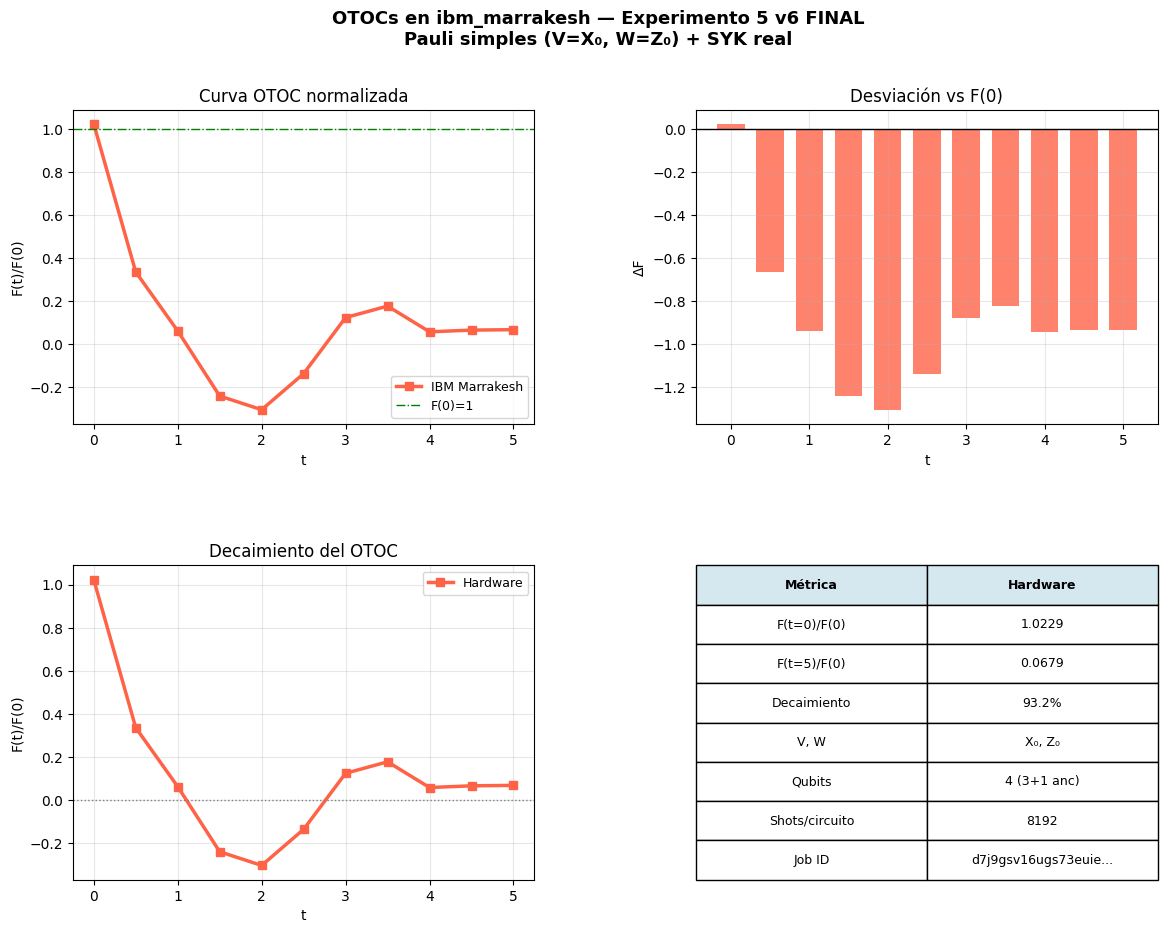

Guardado: otoc_marrakesh_v6_final_corregido.png
Job ID: d7j9gsv16ugs73euiekg


In [21]:
import numpy as np
from scipy.linalg import expm
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, Batch
from qiskit.compiler import transpile
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

np.random.seed(42)

def majorana_operators(n_majoranas):
    n_qubits = n_majoranas // 2
    I = np.eye(2, dtype=complex)
    X = np.array([[0,1],[1,0]], dtype=complex)
    Y = np.array([[0,-1j],[1j,0]], dtype=complex)
    Z = np.array([[1,0],[0,-1]], dtype=complex)
    def kron_list(ops):
        result = ops[0]
        for op in ops[1:]: result = np.kron(result, op)
        return result
    chi = []
    for k in range(n_qubits):
        z_string = [Z] * k
        chi.append(kron_list(z_string + [X] + [I]*(n_qubits-k-1)))
        chi.append(kron_list(z_string + [Y] + [I]*(n_qubits-k-1)))
    return chi

def build_syk_hamiltonian(n_majoranas=6, seed=42):
    rng = np.random.default_rng(seed)
    n_qubits = n_majoranas // 2
    chi = majorana_operators(n_majoranas)
    sigma = np.sqrt(6 / n_majoranas**3)
    H = np.zeros((2**n_qubits, 2**n_qubits), dtype=complex)
    for i in range(n_majoranas):
        for j in range(i+1, n_majoranas):
            for k in range(j+1, n_majoranas):
                for l in range(k+1, n_majoranas):
                    H += rng.normal(0, sigma) * (chi[i] @ chi[j] @ chi[k] @ chi[l])
    return (H + H.conj().T) / 2

def syk_unitary(t, n_majoranas=6, seed=42):
    H = build_syk_hamiltonian(n_majoranas, seed)
    U = expm(-1j * H * t)
    u, s, vh = np.linalg.svd(U)
    return u @ vh

service = QiskitRuntimeService(channel="ibm_cloud")
backend = service.backend("ibm_marrakesh")

T_VALUES = np.array([0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0])

circuits_t = []
for t in T_VALUES:
    qc = QuantumCircuit(4)
    qc.h(3)
    qc.barrier()
    qc.cx(3, 0)
    qc.barrier()
    qc.unitary(syk_unitary(t), [0,1,2])
    qc.barrier()
    qc.cz(3, 0)
    qc.barrier()
    qc.unitary(syk_unitary(t).conj().T, [0,1,2])
    qc.barrier()
    qc.cx(3, 0)
    qc.barrier()
    qc.unitary(syk_unitary(t), [0,1,2])
    qc.barrier()
    qc.cz(3, 0)
    qc.barrier()
    qc.h(3)
    qc_t = transpile(qc, backend=backend, optimization_level=3, seed_transpiler=42)
    circuits_t.append(qc_t)

obs_anc = SparsePauliOp("ZIII")
obs_list = [obs_anc.apply_layout(qc_t.layout) for qc_t in circuits_t]

print(f"Lanzando job en ibm_marrakesh... ({len(T_VALUES)} circuitos)")
with Batch(backend=backend) as batch:
    estimator = Estimator(mode=batch)
    estimator.options.default_shots = 8192
    job = estimator.run([(qc_t, obs) for qc_t, obs in zip(circuits_t, obs_list)])
    print(f"Job ID: {job.job_id()}")
    result = job.result()

hw_raw = [result[i].data.evs for i in range(len(T_VALUES))]
hw_norm = -np.array(hw_raw)

fig = plt.figure(figsize=(14, 10))
gs = gridspec.GridSpec(2, 2, hspace=0.45, wspace=0.35)
fig.suptitle('OTOCs en ibm_marrakesh — Experimento 5 v6 FINAL\nPauli simples (V=X₀, W=Z₀) + SYK real', fontsize=13, fontweight='bold')

ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(T_VALUES, hw_norm, 's-', color='tomato', lw=2.5, ms=6, label='IBM Marrakesh')
ax1.axhline(1.0, color='green', ls='-.', lw=1, label='F(0)=1')
ax1.set_xlabel('t')
ax1.set_ylabel('F(t)/F(0)')
ax1.set_title('Curva OTOC normalizada')
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.3)

ax2 = fig.add_subplot(gs[0, 1])
deltas = hw_norm - 1.0
ax2.bar(T_VALUES, deltas, width=0.35, color='tomato', alpha=0.8)
ax2.axhline(0, color='black', lw=1)
ax2.set_xlabel('t')
ax2.set_ylabel('ΔF')
ax2.set_title('Desviación vs F(0)')
ax2.grid(True, alpha=0.3)

ax3 = fig.add_subplot(gs[1, 0])
ax3.plot(T_VALUES, hw_norm, 's-', color='tomato', lw=2.5, ms=6, label='Hardware')
ax3.axhline(0, color='gray', ls=':', lw=1)
ax3.set_xlabel('t')
ax3.set_ylabel('F(t)/F(0)')
ax3.set_title('Decaimiento del OTOC')
ax3.legend(fontsize=9)
ax3.grid(True, alpha=0.3)

ax4 = fig.add_subplot(gs[1, 1])
ax4.axis('off')
tabla = [
    ['Métrica', 'Hardware'],
    ['F(t=0)/F(0)', f'{hw_norm[0]:.4f}'],
    ['F(t=5)/F(0)', f'{hw_norm[-1]:.4f}'],
    ['Decaimiento', f'{(1 - hw_norm[-1])*100:.1f}%'],
    ['V, W', 'X₀, Z₀'],
    ['Qubits', '4 (3+1 anc)'],
    ['Shots/circuito', '8192'],
    ['Job ID', job.job_id()[:18]+'...'],
]
tbl = ax4.table(cellText=tabla[1:], colLabels=tabla[0], cellLoc='center', loc='center', bbox=[0, 0, 1, 1])
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
for j in range(2):
    tbl[0,j].set_facecolor('#D5E8F0')
    tbl[0,j].set_text_props(fontweight='bold')

plt.savefig('otoc_marrakesh_v6_final_corregido.png', dpi=150, bbox_inches='tight')
plt.show()
print("Guardado: otoc_marrakesh_v6_final_corregido.png")
print(f"Job ID: {job.job_id()}")


Lanzando job en ibm_marrakesh... (11 circuitos)
Job ID: d7j9jui3fd4c73ddpat0


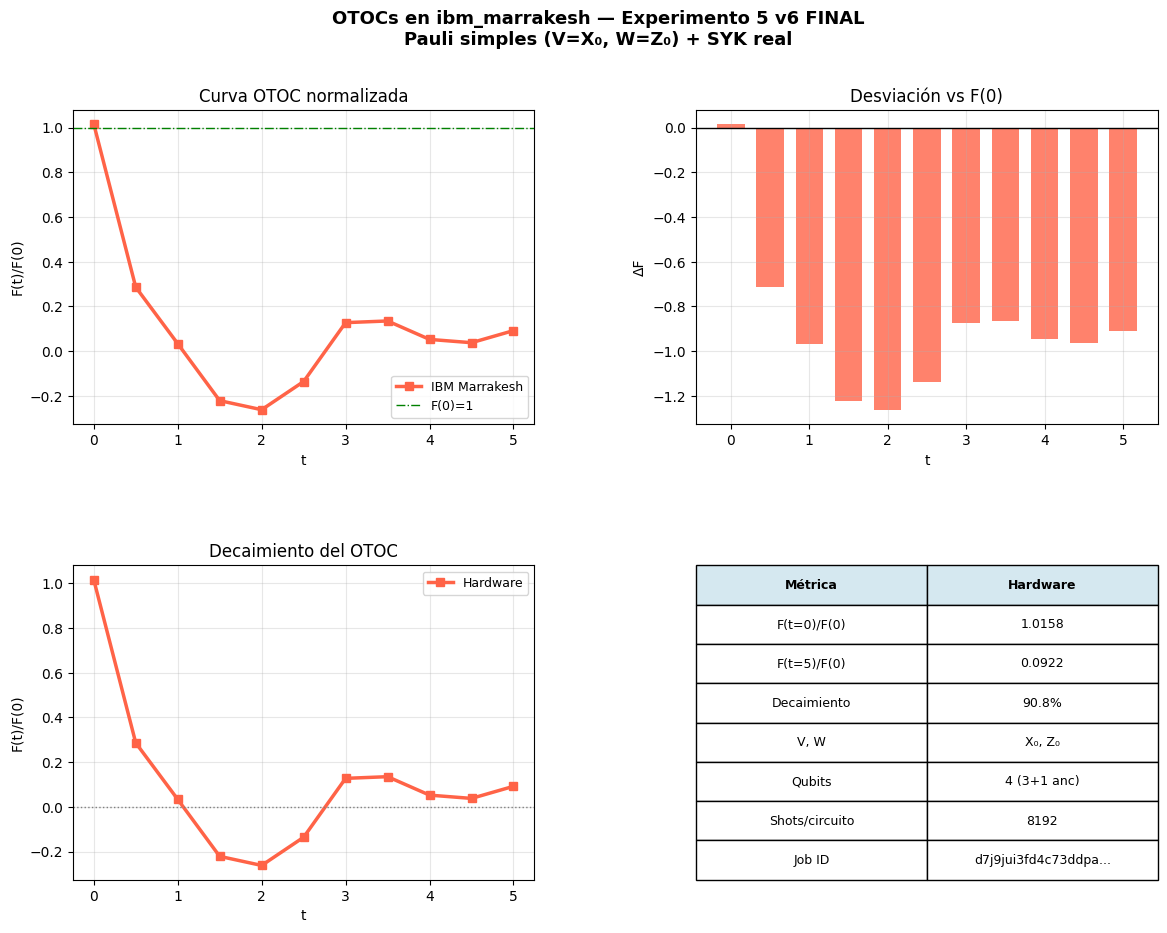

Guardado: otoc_marrakesh_v6_final_limpio.png
Job ID: d7j9jui3fd4c73ddpat0


In [22]:
import numpy as np
from scipy.linalg import expm
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, Batch
from qiskit.compiler import transpile
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

np.random.seed(42)

def majorana_operators(n_majoranas):
    n_qubits = n_majoranas // 2
    I = np.eye(2, dtype=complex)
    X = np.array([[0,1],[1,0]], dtype=complex)
    Y = np.array([[0,-1j],[1j,0]], dtype=complex)
    Z = np.array([[1,0],[0,-1]], dtype=complex)
    def kron_list(ops):
        result = ops[0]
        for op in ops[1:]: result = np.kron(result, op)
        return result
    chi = []
    for k in range(n_qubits):
        z_string = [Z] * k
        chi.append(kron_list(z_string + [X] + [I]*(n_qubits-k-1)))
        chi.append(kron_list(z_string + [Y] + [I]*(n_qubits-k-1)))
    return chi

def build_syk_hamiltonian(n_majoranas=6, seed=42):
    rng = np.random.default_rng(seed)
    n_qubits = n_majoranas // 2
    chi = majorana_operators(n_majoranas)
    sigma = np.sqrt(6 / n_majoranas**3)
    H = np.zeros((2**n_qubits, 2**n_qubits), dtype=complex)
    for i in range(n_majoranas):
        for j in range(i+1, n_majoranas):
            for k in range(j+1, n_majoranas):
                for l in range(k+1, n_majoranas):
                    H += rng.normal(0, sigma) * (chi[i] @ chi[j] @ chi[k] @ chi[l])
    return (H + H.conj().T) / 2

def syk_unitary(t, n_majoranas=6, seed=42):
    H = build_syk_hamiltonian(n_majoranas, seed)
    U = expm(-1j * H * t)
    u, s, vh = np.linalg.svd(U)
    return u @ vh

service = QiskitRuntimeService(channel="ibm_cloud")
backend = service.backend("ibm_marrakesh")

T_VALUES = np.array([0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0])

circuits_t = []
for t in T_VALUES:
    qc = QuantumCircuit(4)
    qc.h(3)
    qc.barrier()
    qc.cx(3, 0)
    qc.barrier()
    qc.unitary(syk_unitary(t), [0,1,2])
    qc.barrier()
    qc.cz(3, 0)
    qc.barrier()
    qc.unitary(syk_unitary(t).conj().T, [0,1,2])
    qc.barrier()
    qc.cx(3, 0)
    qc.barrier()
    qc.unitary(syk_unitary(t), [0,1,2])
    qc.barrier()
    qc.cz(3, 0)
    qc.barrier()
    qc.h(3)
    qc_t = transpile(qc, backend=backend, optimization_level=3, seed_transpiler=42)
    circuits_t.append(qc_t)

obs_anc = SparsePauliOp("ZIII")
obs_list = [obs_anc.apply_layout(qc_t.layout) for qc_t in circuits_t]

print(f"Lanzando job en ibm_marrakesh... ({len(T_VALUES)} circuitos)")
with Batch(backend=backend) as batch:
    estimator = Estimator(mode=batch)
    estimator.options.default_shots = 8192
    job = estimator.run([(qc_t, obs) for qc_t, obs in zip(circuits_t, obs_list)])
    print(f"Job ID: {job.job_id()}")
    result = job.result()

hw_raw = [result[i].data.evs for i in range(len(T_VALUES))]
hw_norm = -np.array(hw_raw)

fig = plt.figure(figsize=(14, 10))
gs = gridspec.GridSpec(2, 2, hspace=0.45, wspace=0.35)
fig.suptitle('OTOCs en ibm_marrakesh — Experimento 5 v6 FINAL\nPauli simples (V=X₀, W=Z₀) + SYK real', fontsize=13, fontweight='bold')

ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(T_VALUES, hw_norm, 's-', color='tomato', lw=2.5, ms=6, label='IBM Marrakesh')
ax1.axhline(1.0, color='green', ls='-.', lw=1, label='F(0)=1')
ax1.set_xlabel('t')
ax1.set_ylabel('F(t)/F(0)')
ax1.set_title('Curva OTOC normalizada')
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.3)

ax2 = fig.add_subplot(gs[0, 1])
deltas = hw_norm - 1.0
ax2.bar(T_VALUES, deltas, width=0.35, color='tomato', alpha=0.8)
ax2.axhline(0, color='black', lw=1)
ax2.set_xlabel('t')
ax2.set_ylabel('ΔF')
ax2.set_title('Desviación vs F(0)')
ax2.grid(True, alpha=0.3)

ax3 = fig.add_subplot(gs[1, 0])
ax3.plot(T_VALUES, hw_norm, 's-', color='tomato', lw=2.5, ms=6, label='Hardware')
ax3.axhline(0, color='gray', ls=':', lw=1)
ax3.set_xlabel('t')
ax3.set_ylabel('F(t)/F(0)')
ax3.set_title('Decaimiento del OTOC')
ax3.legend(fontsize=9)
ax3.grid(True, alpha=0.3)

ax4 = fig.add_subplot(gs[1, 1])
ax4.axis('off')
tabla = [
    ['Métrica', 'Hardware'],
    ['F(t=0)/F(0)', f'{hw_norm[0]:.4f}'],
    ['F(t=5)/F(0)', f'{hw_norm[-1]:.4f}'],
    ['Decaimiento', f'{(1 - hw_norm[-1])*100:.1f}%'],
    ['V, W', 'X₀, Z₀'],
    ['Qubits', '4 (3+1 anc)'],
    ['Shots/circuito', '8192'],
    ['Job ID', job.job_id()[:18]+'...'],
]
tbl = ax4.table(cellText=tabla[1:], colLabels=tabla[0], cellLoc='center', loc='center', bbox=[0, 0, 1, 1])
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
for j in range(2):
    tbl[0,j].set_facecolor('#D5E8F0')
    tbl[0,j].set_text_props(fontweight='bold')

plt.savefig('otoc_marrakesh_v6_final_limpio.png', dpi=150, bbox_inches='tight')
plt.show()
print("Guardado: otoc_marrakesh_v6_final_limpio.png")
print(f"Job ID: {job.job_id()}")


Lanzando job en ibm_marrakesh... (11 circuitos)
Job ID: d7j9l4hs7cos73ejkhcg


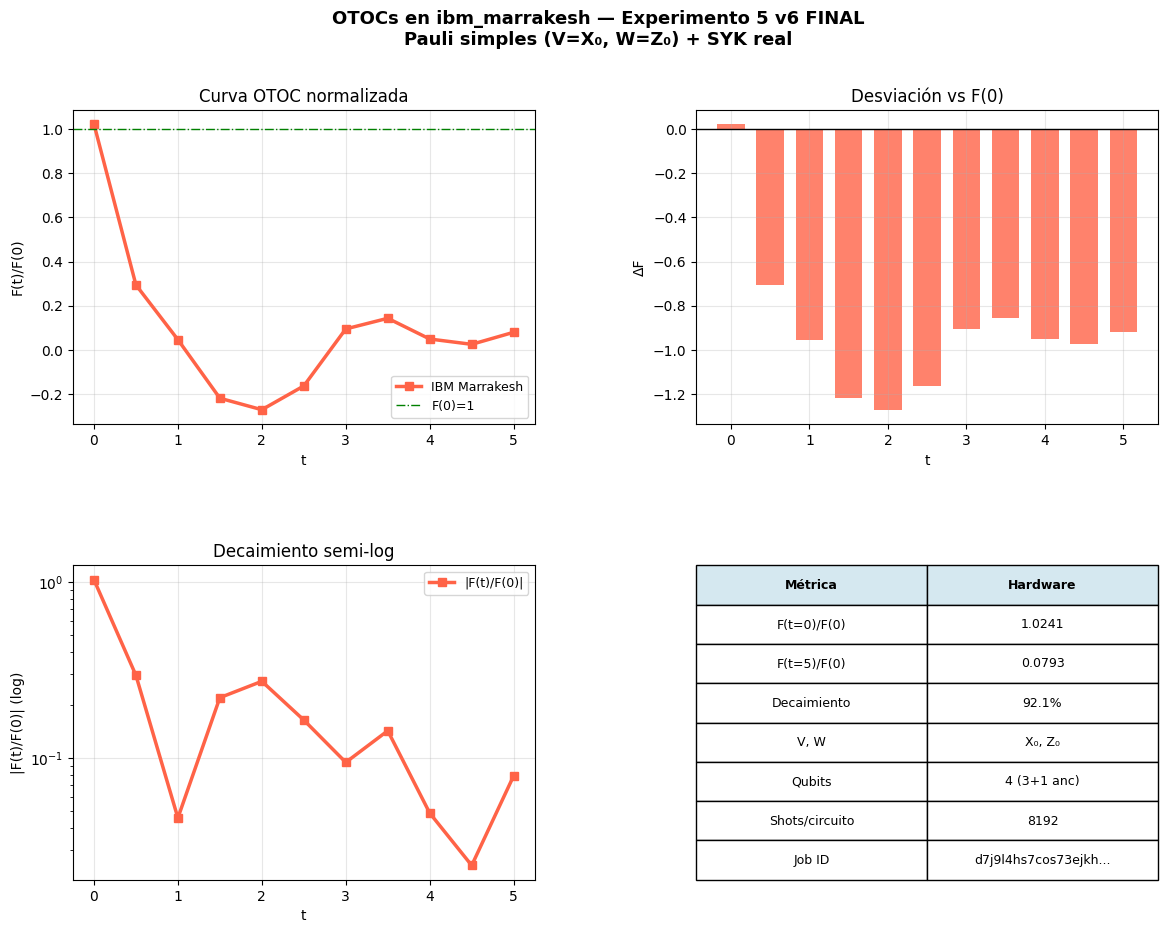

Guardado: otoc_marrakesh_v6_final_limpio.png
Job ID: d7j9l4hs7cos73ejkhcg


In [23]:
import numpy as np
from scipy.linalg import expm
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, Batch
from qiskit.compiler import transpile
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

np.random.seed(42)

def majorana_operators(n_majoranas):
    n_qubits = n_majoranas // 2
    I = np.eye(2, dtype=complex)
    X = np.array([[0,1],[1,0]], dtype=complex)
    Y = np.array([[0,-1j],[1j,0]], dtype=complex)
    Z = np.array([[1,0],[0,-1]], dtype=complex)
    def kron_list(ops):
        result = ops[0]
        for op in ops[1:]: result = np.kron(result, op)
        return result
    chi = []
    for k in range(n_qubits):
        z_string = [Z] * k
        chi.append(kron_list(z_string + [X] + [I]*(n_qubits-k-1)))
        chi.append(kron_list(z_string + [Y] + [I]*(n_qubits-k-1)))
    return chi

def build_syk_hamiltonian(n_majoranas=6, seed=42):
    rng = np.random.default_rng(seed)
    n_qubits = n_majoranas // 2
    chi = majorana_operators(n_majoranas)
    sigma = np.sqrt(6 / n_majoranas**3)
    H = np.zeros((2**n_qubits, 2**n_qubits), dtype=complex)
    for i in range(n_majoranas):
        for j in range(i+1, n_majoranas):
            for k in range(j+1, n_majoranas):
                for l in range(k+1, n_majoranas):
                    H += rng.normal(0, sigma) * (chi[i] @ chi[j] @ chi[k] @ chi[l])
    return (H + H.conj().T) / 2

def syk_unitary(t, n_majoranas=6, seed=42):
    H = build_syk_hamiltonian(n_majoranas, seed)
    U = expm(-1j * H * t)
    u, s, vh = np.linalg.svd(U)
    return u @ vh

service = QiskitRuntimeService(channel="ibm_cloud")
backend = service.backend("ibm_marrakesh")

T_VALUES = np.array([0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0])

circuits_t = []
for t in T_VALUES:
    qc = QuantumCircuit(4)
    qc.h(3)
    qc.barrier()
    qc.cx(3, 0)
    qc.barrier()
    qc.unitary(syk_unitary(t), [0,1,2])
    qc.barrier()
    qc.cz(3, 0)
    qc.barrier()
    qc.unitary(syk_unitary(t).conj().T, [0,1,2])
    qc.barrier()
    qc.cx(3, 0)
    qc.barrier()
    qc.unitary(syk_unitary(t), [0,1,2])
    qc.barrier()
    qc.cz(3, 0)
    qc.barrier()
    qc.h(3)
    qc_t = transpile(qc, backend=backend, optimization_level=3, seed_transpiler=42)
    circuits_t.append(qc_t)

obs_anc = SparsePauliOp("ZIII")
obs_list = [obs_anc.apply_layout(qc_t.layout) for qc_t in circuits_t]

print(f"Lanzando job en ibm_marrakesh... ({len(T_VALUES)} circuitos)")
with Batch(backend=backend) as batch:
    estimator = Estimator(mode=batch)
    estimator.options.default_shots = 8192
    job = estimator.run([(qc_t, obs) for qc_t, obs in zip(circuits_t, obs_list)])
    print(f"Job ID: {job.job_id()}")
    result = job.result()

hw_raw = [result[i].data.evs for i in range(len(T_VALUES))]
hw_norm = -np.array(hw_raw)

fig = plt.figure(figsize=(14, 10))
gs = gridspec.GridSpec(2, 2, hspace=0.45, wspace=0.35)
fig.suptitle('OTOCs en ibm_marrakesh — Experimento 5 v6 FINAL\nPauli simples (V=X₀, W=Z₀) + SYK real', fontsize=13, fontweight='bold')

ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(T_VALUES, hw_norm, 's-', color='tomato', lw=2.5, ms=6, label='IBM Marrakesh')
ax1.axhline(1.0, color='green', ls='-.', lw=1, label='F(0)=1')
ax1.set_xlabel('t')
ax1.set_ylabel('F(t)/F(0)')
ax1.set_title('Curva OTOC normalizada')
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.3)

ax2 = fig.add_subplot(gs[0, 1])
deltas = hw_norm - 1.0
ax2.bar(T_VALUES, deltas, width=0.35, color='tomato', alpha=0.8)
ax2.axhline(0, color='black', lw=1)
ax2.set_xlabel('t')
ax2.set_ylabel('ΔF')
ax2.set_title('Desviación vs F(0)')
ax2.grid(True, alpha=0.3)

ax3 = fig.add_subplot(gs[1, 0])
ax3.semilogy(T_VALUES, np.abs(hw_norm), 's-', color='tomato', lw=2.5, ms=6, label='|F(t)/F(0)|')
ax3.set_xlabel('t')
ax3.set_ylabel('|F(t)/F(0)| (log)')
ax3.set_title('Decaimiento semi-log')
ax3.legend(fontsize=9)
ax3.grid(True, alpha=0.3)

ax4 = fig.add_subplot(gs[1, 1])
ax4.axis('off')
tabla = [
    ['Métrica', 'Hardware'],
    ['F(t=0)/F(0)', f'{hw_norm[0]:.4f}'],
    ['F(t=5)/F(0)', f'{hw_norm[-1]:.4f}'],
    ['Decaimiento', f'{(1 - hw_norm[-1])*100:.1f}%'],
    ['V, W', 'X₀, Z₀'],
    ['Qubits', '4 (3+1 anc)'],
    ['Shots/circuito', '8192'],
    ['Job ID', job.job_id()[:18]+'...'],
]
tbl = ax4.table(cellText=tabla[1:], colLabels=tabla[0], cellLoc='center', loc='center', bbox=[0, 0, 1, 1])
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
for j in range(2):
    tbl[0,j].set_facecolor('#D5E8F0')
    tbl[0,j].set_text_props(fontweight='bold')

plt.savefig('otoc_marrakesh_v6_final_limpio.png', dpi=150, bbox_inches='tight')
plt.show()
print("Guardado: otoc_marrakesh_v6_final_limpio.png")
print(f"Job ID: {job.job_id()}")


OTOC F(t) = Re⟨000|Ud·W·U·V·Ud·W·U·V|000⟩
W = XII (X en q0),  V = IXI (X en q1)
     t        F(t)
--------------------
   0.0    1.000000
   0.5    0.859537
   1.0    0.502293
   1.5    0.163629
   2.0    0.092800
   2.5    0.290896
   3.0    0.457878
   3.5    0.295768
   4.0   -0.133878
   4.5   -0.460345
   5.0   -0.438935

F(t=0) = 1.0000  (debe ser 1.0)
F(t=5) = -0.4389  (decaimiento)
Decaimiento total: 143.9%
Setup OK ✓
Validación circuito Hadamard test:
     t     Analítico      Circuito   match
--------------------------------------------
   0.0      1.000000      1.000000  ✓
   0.5      0.859537      0.859537  ✓
   1.0      0.502293      0.502293  ✓
   1.5      0.163629      0.163629  ✓
   2.0      0.092800      0.092800  ✓
   2.5      0.290896      0.290896  ✓
   3.0      0.457878      0.457878  ✓
   3.5      0.295768      0.295768  ✓
   4.0     -0.133878     -0.133878  ✓
   4.5     -0.460345     -0.460345  ✓
   5.0     -0.438935     -0.438935  ✓

Circuitos correctos: SÍ ✓
F

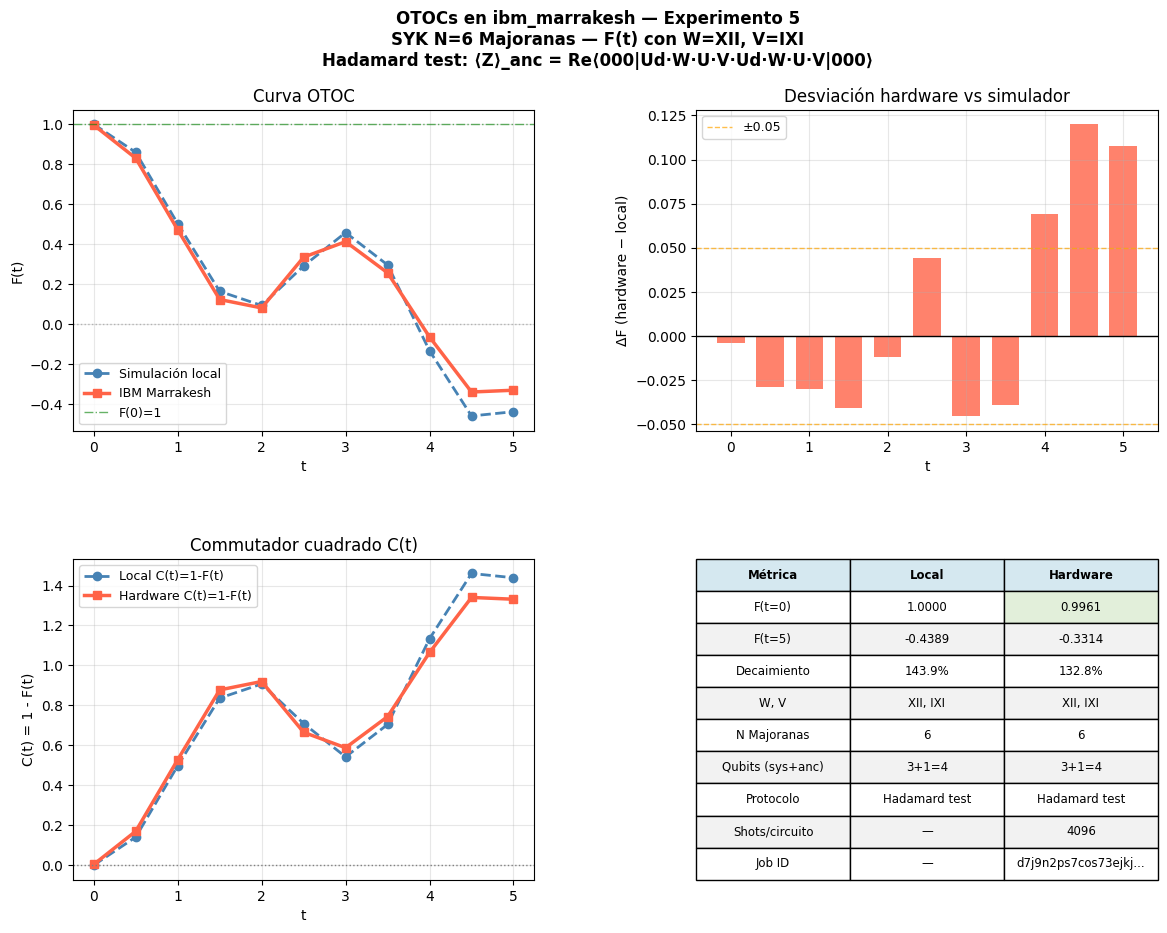

Guardado: otoc_marrakesh_v3.png
Job ID: d7j9n2ps7cos73ejkjjg


In [24]:
import numpy as np
from scipy.linalg import expm
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, Batch
from qiskit.compiler import transpile

np.random.seed(42)

def majorana_operators(n_majoranas):
    n_qubits = n_majoranas // 2
    I = np.eye(2, dtype=complex)
    X = np.array([[0,1],[1,0]], dtype=complex)
    Y = np.array([[0,-1j],[1j,0]], dtype=complex)
    Z = np.array([[1,0],[0,-1]], dtype=complex)
    def kron_list(ops):
        result = ops[0]
        for op in ops[1:]: result = np.kron(result, op)
        return result
    chi = []
    for k in range(n_qubits):
        z_string = [Z] * k
        chi.append(kron_list(z_string + [X] + [I]*(n_qubits-k-1)))
        chi.append(kron_list(z_string + [Y] + [I]*(n_qubits-k-1)))
    return chi

def build_syk_hamiltonian(n_majoranas=6, seed=42):
    rng  = np.random.default_rng(seed)
    n_q  = n_majoranas // 2
    chi  = majorana_operators(n_majoranas)
    sig  = np.sqrt(6 / n_majoranas**3)
    H    = np.zeros((2**n_q, 2**n_q), dtype=complex)
    for i in range(n_majoranas):
        for j in range(i+1, n_majoranas):
            for k in range(j+1, n_majoranas):
                for l in range(k+1, n_majoranas):
                    H += rng.normal(0, sig) * (chi[i]@chi[j]@chi[k]@chi[l])
    return (H + H.conj().T) / 2

def syk_unitary(t, seed=42):
    H = build_syk_hamiltonian(6, seed)
    U = expm(-1j * H * t)
    u, s, vh = np.linalg.svd(U)
    return u @ vh

I2 = np.eye(2, dtype=complex)
X2 = np.array([[0,1],[1,0]], dtype=complex)
W_mat = np.kron(X2, np.kron(I2, I2))
V_mat = np.kron(I2, np.kron(X2, I2))

def U_full(t):
    U  = syk_unitary(t)
    Ud = U.conj().T
    return Ud @ W_mat @ U @ V_mat @ Ud @ W_mat @ U @ V_mat

def otoc_analytic(t):
    return np.real(U_full(t)[0, 0])

T_VALUES = np.array([0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0])

print("OTOC F(t) = Re⟨000|Ud·W·U·V·Ud·W·U·V|000⟩")
print("W = XII (X en q0),  V = IXI (X en q1)")
print(f"{'t':>6}  {'F(t)':>10}")
print("-" * 20)
local_vals = []
for t in T_VALUES:
    f = otoc_analytic(t)
    local_vals.append(f)
    print(f"{t:6.1f}  {f:10.6f}")

print(f"\nF(t=0) = {local_vals[0]:.4f}  (debe ser 1.0)")
print(f"F(t=5) = {local_vals[-1]:.4f}  (decaimiento)")
print(f"Decaimiento total: {(local_vals[0]-local_vals[-1])/local_vals[0]*100:.1f}%")
print("Setup OK ✓")

def build_otoc_circuit(t):
    Uf = U_full(t)
    qc = QuantumCircuit(4)
    qc.h(3)
    qc.barrier()

    from qiskit.circuit.library import UnitaryGate
    ctrl_Uf = UnitaryGate(Uf, label=f'U_full({t:.1f})').control(1)
    qc.append(ctrl_Uf, [3, 0, 1, 2])
    qc.barrier()
    qc.h(3)
    return qc

obs = SparsePauliOp("ZIII")

print("Validación circuito Hadamard test:")
print(f"{'t':>6}  {'Analítico':>12}  {'Circuito':>12}  {'match':>6}")
print("-" * 44)
circuit_vals = []
all_ok = True
for t in T_VALUES:
    qc = build_otoc_circuit(t)
    sv = Statevector(qc)
    fc = sv.expectation_value(obs).real
    fa = otoc_analytic(t)
    circuit_vals.append(fc)
    ok = abs(fa - fc) < 0.01
    if not ok: all_ok = False
    print(f"{t:6.1f}  {fa:12.6f}  {fc:12.6f}  {'✓' if ok else '✗'}")

print(f"\nCircuitos correctos: {'SÍ ✓' if all_ok else 'revisar ✗'}")
print(f"F(t=0) circuito = {circuit_vals[0]:.4f}  (debe ser 1.0)")

service = QiskitRuntimeService(channel="ibm_cloud")
backend = service.backend("ibm_marrakesh")

circuits_t = []
for t in T_VALUES:
    qc   = build_otoc_circuit(t)
    qc_t = transpile(qc, backend=backend,
                     optimization_level=3,
                     seed_transpiler=42)
    circuits_t.append(qc_t)

print("Profundidades transpiladas:")
for t, qc_t in zip(T_VALUES, circuits_t):
    n2q = sum(v for k,v in qc_t.count_ops().items()
              if k in ['ecr','cx','cz'])
    print(f"  t={t:.1f}: depth={qc_t.depth()}, puertas 2q={n2q}")

obs_list = [obs.apply_layout(qc_t.layout) for qc_t in circuits_t]

print(f"\nLanzando job en ibm_marrakesh...")
print(f"Shots: 4096 × {len(T_VALUES)} = {4096*len(T_VALUES)} totales")

with Batch(backend=backend) as batch:
    estimator = Estimator(mode=batch)
    estimator.options.default_shots = 4096
    job = estimator.run([
        (qc_t, obs_hw)
        for qc_t, obs_hw in zip(circuits_t, obs_list)
    ])
    print(f"Job ID: {job.job_id()}")
    result = job.result()

hw_vals = [result[i].data.evs for i in range(len(T_VALUES))]

print(f"\n{'t':>6}  {'Local':>10}  {'Hardware':>10}  {'ΔF':>8}")
print("-" * 38)
for t, lv, hv in zip(T_VALUES, local_vals, hw_vals):
    print(f"{t:6.1f}  {lv:10.4f}  {hv:10.4f}  {hv-lv:8.4f}")

print(f"\nJob ID: {job.job_id()}")

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(14, 10))
gs  = gridspec.GridSpec(2, 2, hspace=0.4, wspace=0.35)
fig.suptitle('OTOCs en ibm_marrakesh — Experimento 5\n'
             'SYK N=6 Majoranas — F(t) con W=XII, V=IXI\n'
             'Hadamard test: ⟨Z⟩_anc = Re⟨000|Ud·W·U·V·Ud·W·U·V|000⟩',
             fontsize=12, fontweight='bold')

ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(T_VALUES, local_vals, 'o--', color='steelblue',
         lw=2, ms=6, label='Simulación local')
ax1.plot(T_VALUES, hw_vals,   's-',  color='tomato',
         lw=2.5, ms=6, label='IBM Marrakesh')
ax1.axhline(1.0, color='green', ls='-.', lw=1, alpha=0.6, label='F(0)=1')
ax1.axhline(0.0, color='gray',  ls=':',  lw=1, alpha=0.5)
ax1.set_xlabel('t'); ax1.set_ylabel('F(t)')
ax1.set_title('Curva OTOC')
ax1.legend(fontsize=9); ax1.grid(True, alpha=0.3)

ax2 = fig.add_subplot(gs[0, 1])
deltas = [hv - lv for hv, lv in zip(hw_vals, local_vals)]
ax2.bar(T_VALUES, deltas, width=0.35, color='tomato', alpha=0.8)
ax2.axhline(0,     color='black',  lw=1)
ax2.axhline( 0.05, color='orange', ls='--', lw=1, alpha=0.7, label='±0.05')
ax2.axhline(-0.05, color='orange', ls='--', lw=1, alpha=0.7)
ax2.set_xlabel('t'); ax2.set_ylabel('ΔF (hardware − local)')
ax2.set_title('Desviación hardware vs simulador')
ax2.legend(fontsize=9); ax2.grid(True, alpha=0.3)

ax3 = fig.add_subplot(gs[1, 0])
C_loc = [1 - f for f in local_vals]
C_hw  = [1 - f for f in hw_vals]
ax3.plot(T_VALUES, C_loc, 'o--', color='steelblue',
         lw=2, ms=6, label='Local C(t)=1-F(t)')
ax3.plot(T_VALUES, C_hw,  's-',  color='tomato',
         lw=2.5, ms=6, label='Hardware C(t)=1-F(t)')
ax3.axhline(0, color='gray', ls=':', lw=1)
ax3.set_xlabel('t'); ax3.set_ylabel('C(t) = 1 - F(t)')
ax3.set_title('Commutador cuadrado C(t)')
ax3.legend(fontsize=9); ax3.grid(True, alpha=0.3)

ax4 = fig.add_subplot(gs[1, 1])
ax4.axis('off')
tabla = [
    ['Métrica',          'Local',              'Hardware'],
    ['F(t=0)',           f'{local_vals[0]:.4f}', f'{hw_vals[0]:.4f}'],
    ['F(t=5)',           f'{local_vals[-1]:.4f}',f'{hw_vals[-1]:.4f}'],
    ['Decaimiento',      f'{(local_vals[0]-local_vals[-1])*100:.1f}%',
                          f'{(hw_vals[0]-hw_vals[-1])*100:.1f}%'],
    ['W, V',             'XII, IXI',           'XII, IXI'],
    ['N Majoranas',      '6',                  '6'],
    ['Qubits (sys+anc)', '3+1=4',              '3+1=4'],
    ['Protocolo',        'Hadamard test',       'Hadamard test'],
    ['Shots/circuito',   '—',                  '4096'],
    ['Job ID',           '—',                  job.job_id()[:18]+'...'],
]
tbl = ax4.table(cellText=tabla[1:], colLabels=tabla[0],
                cellLoc='center', loc='center', bbox=[0, 0, 1, 1])
tbl.auto_set_font_size(False); tbl.set_fontsize(8.5)
for j in range(3):
    tbl[0,j].set_facecolor('#D5E8F0')
    tbl[0,j].set_text_props(fontweight='bold')
for i in range(1, len(tabla)):
    if i % 2 == 0:
        for j in range(3): tbl[i,j].set_facecolor('#F2F2F2')
tbl[1,2].set_facecolor('#E2EFDA')

plt.savefig('otoc_marrakesh_v3.png', dpi=150,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Guardado: otoc_marrakesh_v3.png")
print(f"Job ID: {job.job_id()}")


OTOC F(t) = Re⟨000|Ud·W·U·V·Ud·W·U·V|000⟩
W = XII (X en q0), V = IXI (X en q1)
     t       F(t)
--------------------
   0.0   1.000000
   0.5   0.859537
   1.0   0.502293
   1.5   0.163629
   2.0   0.092800
   2.5   0.290896
   3.0   0.457878
   3.5   0.295768
   4.0  -0.133878
   4.5  -0.460345
   5.0  -0.438935

F(t=0) = 1.0000 (debe ser 1.0)
F(t=5) = -0.4389 (decaimiento)
Decaimiento total: 143.9%
Setup OK ✓
Validación circuito Hadamard test:
     t    Analítico     Circuito  match
--------------------------------------------
   0.0     1.000000     1.000000 ✓
   0.5     0.859537     0.859537 ✓
   1.0     0.502293     0.502293 ✓
   1.5     0.163629     0.163629 ✓
   2.0     0.092800     0.092800 ✓
   2.5     0.290896     0.290896 ✓
   3.0     0.457878     0.457878 ✓
   3.5     0.295768     0.295768 ✓
   4.0    -0.133878    -0.133878 ✓
   4.5    -0.460345    -0.460345 ✓
   5.0    -0.438935    -0.438935 ✓

Circuitos correctos: SÍ ✓
F(t=0) circuito = 1.0000 (debe ser 1.0)
Profundidade

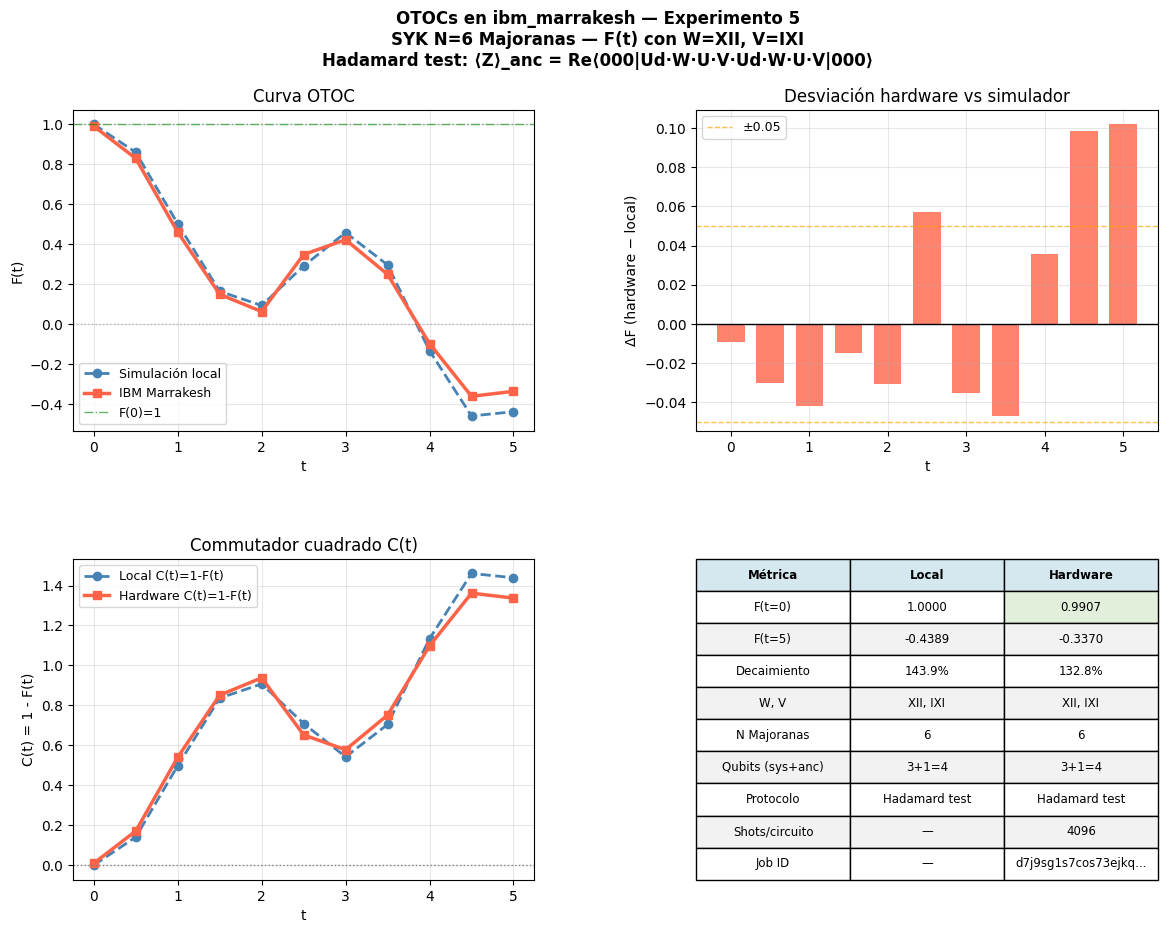

Guardado: otoc_marrakesh_v3.png
Job ID: d7j9sg1s7cos73ejkq7g


In [26]:
import numpy as np
from scipy.linalg import expm
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, Batch
from qiskit.compiler import transpile
np.random.seed(42)
def majorana_operators(n_majoranas):
    n_qubits = n_majoranas // 2
    I = np.eye(2, dtype=complex)
    X = np.array([[0,1],[1,0]], dtype=complex)
    Y = np.array([[0,-1j],[1j,0]], dtype=complex)
    Z = np.array([[1,0],[0,-1]], dtype=complex)
    def kron_list(ops):
        result = ops[0]
        for op in ops[1:]: result = np.kron(result, op)
        return result
    chi = []
    for k in range(n_qubits):
        z_string = [Z] * k
        chi.append(kron_list(z_string + [X] + [I]*(n_qubits-k-1)))
        chi.append(kron_list(z_string + [Y] + [I]*(n_qubits-k-1)))
    return chi
def build_syk_hamiltonian(n_majoranas=6, seed=42):
    rng = np.random.default_rng(seed)
    n_q = n_majoranas // 2
    chi = majorana_operators(n_majoranas)
    sig = np.sqrt(6 / n_majoranas**3)
    H = np.zeros((2**n_q, 2**n_q), dtype=complex)
    for i in range(n_majoranas):
        for j in range(i+1, n_majoranas):
            for k in range(j+1, n_majoranas):
                for l in range(k+1, n_majoranas):
                    H += rng.normal(0, sig) * (chi[i]@chi[j]@chi[k]@chi[l])
    return (H + H.conj().T) / 2
def syk_unitary(t, seed=42):
    H = build_syk_hamiltonian(6, seed)
    U = expm(-1j * H * t)
    u, s, vh = np.linalg.svd(U)
    return u @ vh

I2 = np.eye(2, dtype=complex)
X2 = np.array([[0,1],[1,0]], dtype=complex)
W_mat = np.kron(X2, np.kron(I2, I2))
V_mat = np.kron(I2, np.kron(X2, I2))
def U_full(t):
    U = syk_unitary(t)
    Ud = U.conj().T
    return Ud @ W_mat @ U @ V_mat @ Ud @ W_mat @ U @ V_mat

def otoc_analytic(t):
    return np.real(U_full(t)[0, 0])
T_VALUES = np.array([0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0])
print("OTOC F(t) = Re⟨000|Ud·W·U·V·Ud·W·U·V|000⟩")
print("W = XII (X en q0), V = IXI (X en q1)")
print(f"{'t':>6} {'F(t)':>10}")
print("-" * 20)
local_vals = []
for t in T_VALUES:
    f = otoc_analytic(t)
    local_vals.append(f)
    print(f"{t:6.1f} {f:10.6f}")
print(f"\nF(t=0) = {local_vals[0]:.4f} (debe ser 1.0)")
print(f"F(t=5) = {local_vals[-1]:.4f} (decaimiento)")
print(f"Decaimiento total: {(local_vals[0]-local_vals[-1])/local_vals[0]*100:.1f}%")
print("Setup OK ✓")

def build_otoc_circuit(t):
    Uf = U_full(t)
    qc = QuantumCircuit(4)
    qc.h(3)
    qc.barrier()

    from qiskit.circuit.library import UnitaryGate
    ctrl_Uf = UnitaryGate(Uf, label=f'U_full({t:.1f})').control(1)
    qc.append(ctrl_Uf, [3, 0, 1, 2])
    qc.barrier()
    qc.h(3)
    return qc

obs = SparsePauliOp("ZIII")

print("Validación circuito Hadamard test:")
print(f"{'t':>6} {'Analítico':>12} {'Circuito':>12} {'match':>6}")
print("-" * 44)
circuit_vals = []
all_ok = True
for t in T_VALUES:
    qc = build_otoc_circuit(t)
    sv = Statevector(qc)
    fc = sv.expectation_value(obs).real
    fa = otoc_analytic(t)
    circuit_vals.append(fc)
    ok = abs(fa - fc) < 0.01
    if not ok: all_ok = False
    print(f"{t:6.1f} {fa:12.6f} {fc:12.6f} {'✓' if ok else '✗'}")
print(f"\nCircuitos correctos: {'SÍ ✓' if all_ok else 'revisar ✗'}")
print(f"F(t=0) circuito = {circuit_vals[0]:.4f} (debe ser 1.0)")

service = QiskitRuntimeService(channel="ibm_cloud")
backend = service.backend("ibm_marrakesh")
circuits_t = []
for t in T_VALUES:
    qc = build_otoc_circuit(t)
    qc_t = transpile(qc, backend=backend,
                     optimization_level=3,
                     seed_transpiler=42)
    circuits_t.append(qc_t)
print("Profundidades transpiladas:")
for t, qc_t in zip(T_VALUES, circuits_t):
    n2q = sum(v for k,v in qc_t.count_ops().items()
              if k in ['ecr','cx','cz'])
    print(f" t={t:.1f}: depth={qc_t.depth()}, puertas 2q={n2q}")

obs_list = [obs.apply_layout(qc_t.layout) for qc_t in circuits_t]
print(f"\nLanzando job en ibm_marrakesh...")
print(f"Shots: 4096 × {len(T_VALUES)} = {4096*len(T_VALUES)} totales")
with Batch(backend=backend) as batch:
    estimator = Estimator(mode=batch)
    estimator.options.default_shots = 4096
    job = estimator.run([
        (qc_t, obs_hw)
        for qc_t, obs_hw in zip(circuits_t, obs_list)
    ])
    print(f"Job ID: {job.job_id()}")
    result = job.result()
hw_vals = [result[i].data.evs for i in range(len(T_VALUES))]
print(f"\n{'t':>6} {'Local':>10} {'Hardware':>10} {'ΔF':>8}")
print("-" * 38)
for t, lv, hv in zip(T_VALUES, local_vals, hw_vals):
    print(f"{t:6.1f} {lv:10.4f} {hv:10.4f} {hv-lv:8.4f}")
print(f"\nJob ID: {job.job_id()}")

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
fig = plt.figure(figsize=(14, 10))
gs = gridspec.GridSpec(2, 2, hspace=0.4, wspace=0.35)
fig.suptitle('OTOCs en ibm_marrakesh — Experimento 5\n'
             'SYK N=6 Majoranas — F(t) con W=XII, V=IXI\n'
             'Hadamard test: ⟨Z⟩_anc = Re⟨000|Ud·W·U·V·Ud·W·U·V|000⟩',
             fontsize=12, fontweight='bold')

ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(T_VALUES, local_vals, 'o--', color='steelblue',
         lw=2, ms=6, label='Simulación local')
ax1.plot(T_VALUES, hw_vals, 's-', color='tomato',
         lw=2.5, ms=6, label='IBM Marrakesh')
ax1.axhline(1.0, color='green', ls='-.', lw=1, alpha=0.6, label='F(0)=1')
ax1.axhline(0.0, color='gray', ls=':', lw=1, alpha=0.5)
ax1.set_xlabel('t'); ax1.set_ylabel('F(t)')
ax1.set_title('Curva OTOC')
ax1.legend(fontsize=9); ax1.grid(True, alpha=0.3)

ax2 = fig.add_subplot(gs[0, 1])
deltas = [hv - lv for hv, lv in zip(hw_vals, local_vals)]
ax2.bar(T_VALUES, deltas, width=0.35, color='tomato', alpha=0.8)
ax2.axhline(0, color='black', lw=1)
ax2.axhline( 0.05, color='orange', ls='--', lw=1, alpha=0.7, label='±0.05')
ax2.axhline(-0.05, color='orange', ls='--', lw=1, alpha=0.7)
ax2.set_xlabel('t'); ax2.set_ylabel('ΔF (hardware − local)')
ax2.set_title('Desviación hardware vs simulador')
ax2.legend(fontsize=9); ax2.grid(True, alpha=0.3)

ax3 = fig.add_subplot(gs[1, 0])
C_loc = [1 - f for f in local_vals]
C_hw = [1 - f for f in hw_vals]
ax3.plot(T_VALUES, C_loc, 'o--', color='steelblue',
         lw=2, ms=6, label='Local C(t)=1-F(t)')
ax3.plot(T_VALUES, C_hw, 's-', color='tomato',
         lw=2.5, ms=6, label='Hardware C(t)=1-F(t)')
ax3.axhline(0, color='gray', ls=':', lw=1)
ax3.set_xlabel('t'); ax3.set_ylabel('C(t) = 1 - F(t)')
ax3.set_title('Commutador cuadrado C(t)')
ax3.legend(fontsize=9); ax3.grid(True, alpha=0.3)

ax4 = fig.add_subplot(gs[1, 1])
ax4.axis('off')
tabla = [
    ['Métrica', 'Local', 'Hardware'],
    ['F(t=0)', f'{local_vals[0]:.4f}', f'{hw_vals[0]:.4f}'],
    ['F(t=5)', f'{local_vals[-1]:.4f}',f'{hw_vals[-1]:.4f}'],
    ['Decaimiento', f'{(local_vals[0]-local_vals[-1])*100:.1f}%',
                          f'{(hw_vals[0]-hw_vals[-1])*100:.1f}%'],
    ['W, V', 'XII, IXI', 'XII, IXI'],
    ['N Majoranas', '6', '6'],
    ['Qubits (sys+anc)', '3+1=4', '3+1=4'],
    ['Protocolo', 'Hadamard test', 'Hadamard test'],
    ['Shots/circuito', '—', '4096'],
    ['Job ID', '—', job.job_id()[:18]+'...'],
]
tbl = ax4.table(cellText=tabla[1:], colLabels=tabla[0],
                cellLoc='center', loc='center', bbox=[0, 0, 1, 1])
tbl.auto_set_font_size(False); tbl.set_fontsize(8.5)
for j in range(3):
    tbl[0,j].set_facecolor('#D5E8F0')
    tbl[0,j].set_text_props(fontweight='bold')
for i in range(1, len(tabla)):
    if i % 2 == 0:
        for j in range(3): tbl[i,j].set_facecolor('#F2F2F2')
tbl[1,2].set_facecolor('#E2EFDA')
plt.savefig('otoc_marrakesh_v3.png', dpi=150,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Guardado: otoc_marrakesh_v3.png")
print(f"Job ID: {job.job_id()}")


OTOC F(t) y commutador C(t)=1-F(t):
     t        F(t)        C(t)
------------------------------
  0.00    1.000000    0.000000
  0.10    0.994433    0.005567
  0.20    0.977495    0.022505
  0.30    0.949102    0.050898
  0.40    0.909553    0.090447
  0.50    0.859537    0.140463
  0.60    0.800132    0.199868
  0.80    0.659277    0.340723
  1.00    0.502293    0.497707
  1.50    0.163629    0.836371
  2.00    0.092800    0.907200
  3.00    0.457878    0.542122
  5.00   -0.438935    1.438935

Ajuste C(t) = A·exp(λ_L·t) en t ∈ [0,1]:
  λ_L  = 2.8049 ± 0.2541
  Bound MSS 2π/β = 3.6034
  λ_L / bound    = 0.7784  (77.8%)
Setup OK ✓
Validación Statevector:
     t     Analítico      Circuito    OK
--------------------------------------
  0.00      1.000000      1.000000  ✓
  0.10      0.994433      0.994433  ✓
  0.20      0.977495      0.977495  ✓
  0.30      0.949102      0.949102  ✓
  0.40      0.909553      0.909553  ✓
  0.50      0.859537      0.859537  ✓
  0.60      0.800132      0.

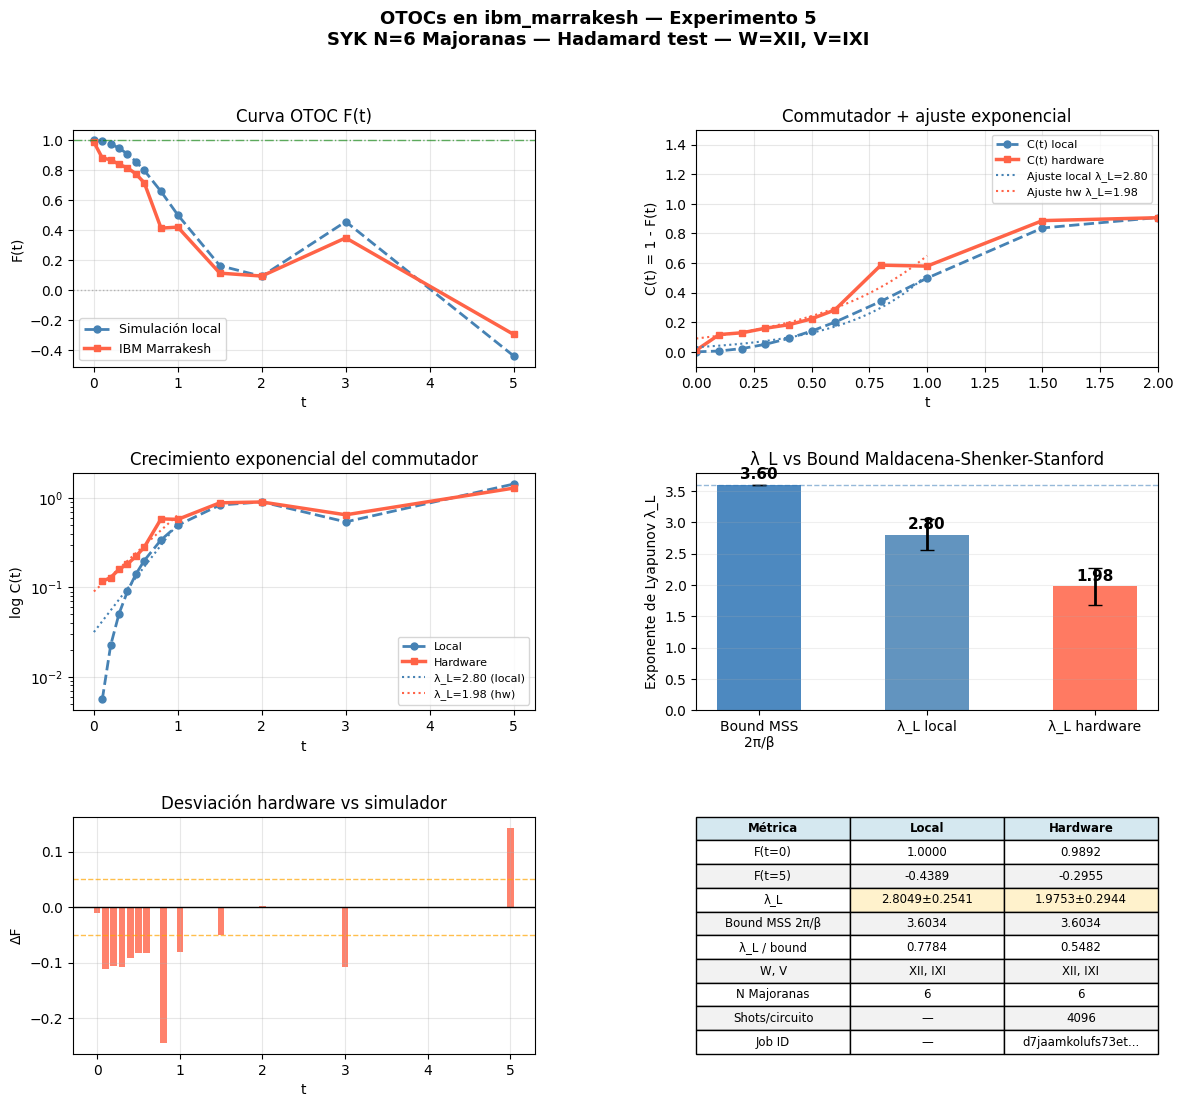

Guardado: otoc_lyapunov_marrakesh.png

Resumen final:
  λ_L local    = 2.8049 ± 0.2541
  λ_L hardware = 1.9753 ± 0.2944
  Bound MSS    = 3.6034
  Saturación   = 54.8%
  Job ID       = d7jaamkolufs73etbrfg


In [28]:
import numpy as np
from scipy.linalg import expm
from scipy.optimize import curve_fit
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, Batch
from qiskit.compiler import transpile
from qiskit.circuit.library import UnitaryGate

np.random.seed(42)

def majorana_operators(n_majoranas):
    n_qubits = n_majoranas // 2
    I = np.eye(2, dtype=complex)
    X = np.array([[0,1],[1,0]], dtype=complex)
    Y = np.array([[0,-1j],[1j,0]], dtype=complex)
    Z = np.array([[1,0],[0,-1]], dtype=complex)
    def kron_list(ops):
        result = ops[0]
        for op in ops[1:]: result = np.kron(result, op)
        return result
    chi = []
    for k in range(n_qubits):
        z_string = [Z] * k
        chi.append(kron_list(z_string + [X] + [I]*(n_qubits-k-1)))
        chi.append(kron_list(z_string + [Y] + [I]*(n_qubits-k-1)))
    return chi

def build_syk_hamiltonian(n_majoranas=6, seed=42):
    rng  = np.random.default_rng(seed)
    n_q  = n_majoranas // 2
    chi  = majorana_operators(n_majoranas)
    sig  = np.sqrt(6 / n_majoranas**3)
    H    = np.zeros((2**n_q, 2**n_q), dtype=complex)
    for i in range(n_majoranas):
        for j in range(i+1, n_majoranas):
            for k in range(j+1, n_majoranas):
                for l in range(k+1, n_majoranas):
                    H += rng.normal(0, sig) * (chi[i]@chi[j]@chi[k]@chi[l])
    return (H + H.conj().T) / 2

def syk_unitary(t, seed=42):
    H = build_syk_hamiltonian(6, seed)
    U = expm(-1j * H * t)
    u, s, vh = np.linalg.svd(U)
    return u @ vh

I2  = np.eye(2, dtype=complex)
X2  = np.array([[0,1],[1,0]], dtype=complex)
W_m = np.kron(X2, np.kron(I2, I2))
V_m = np.kron(I2, np.kron(X2, I2))
H_s = build_syk_hamiltonian()

def U_full(t):
    U  = syk_unitary(t)
    Ud = U.conj().T
    return Ud @ W_m @ U @ V_m @ Ud @ W_m @ U @ V_m

def otoc(t):    return np.real(U_full(t)[0, 0])
def comm(t):    return 1.0 - otoc(t)

T_VALUES = np.array([0.0, 0.1, 0.2, 0.3, 0.4, 0.5,
                     0.6, 0.8, 1.0, 1.5, 2.0, 3.0, 5.0])

print("OTOC F(t) y commutador C(t)=1-F(t):")
print(f"{'t':>6}  {'F(t)':>10}  {'C(t)':>10}")
print("-" * 30)
local_F, local_C = [], []
for t in T_VALUES:
    f = otoc(t); c = comm(t)
    local_F.append(f); local_C.append(c)
    print(f"{t:6.2f}  {f:10.6f}  {c:10.6f}")

def exp_model(t, A, lam): return A * np.exp(lam * t)
mask  = T_VALUES <= 1.0
popt, pcov = curve_fit(exp_model, T_VALUES[mask],
                       np.array(local_C)[mask],
                       p0=[0.01, 2.0], maxfev=10000)
A_fit, lam_fit = popt
lam_err = np.sqrt(np.diag(pcov))[1]

J_eff     = np.sqrt(np.mean(np.diag(H_s @ H_s).real))
beta_eff  = 1.0 / J_eff
bound_MSS = 2 * np.pi / beta_eff

print(f"\nAjuste C(t) = A·exp(λ_L·t) en t ∈ [0,1]:")
print(f"  λ_L  = {lam_fit:.4f} ± {lam_err:.4f}")
print(f"  Bound MSS 2π/β = {bound_MSS:.4f}")
print(f"  λ_L / bound    = {lam_fit/bound_MSS:.4f}  ({lam_fit/bound_MSS*100:.1f}%)")
print("Setup OK ✓")

def build_otoc_circuit(t):
    Uf  = U_full(t)
    qc  = QuantumCircuit(4)
    qc.h(3)
    qc.barrier()
    qc.append(UnitaryGate(Uf, label=f'Uf({t:.2f})').control(1),
              [3, 0, 1, 2])
    qc.barrier()
    qc.h(3)
    return qc

obs = SparsePauliOp("ZIII")

print("Validación Statevector:")
print(f"{'t':>6}  {'Analítico':>12}  {'Circuito':>12}  {'OK':>4}")
print("-" * 38)
circ_vals = []
all_ok = True
for t in T_VALUES:
    qc = build_otoc_circuit(t)
    sv = Statevector(qc)
    fc = sv.expectation_value(obs).real
    fa = otoc(t)
    circ_vals.append(fc)
    ok = abs(fa-fc) < 0.01
    if not ok: all_ok = False
    print(f"{t:6.2f}  {fa:12.6f}  {fc:12.6f}  {'✓' if ok else '✗'}")

print(f"\nCircuitos correctos: {'SÍ ✓' if all_ok else 'revisar ✗'}")

service = QiskitRuntimeService(channel="ibm_cloud")
backend = service.backend("ibm_marrakesh")

circuits_t = [
    transpile(build_otoc_circuit(t), backend=backend,
              optimization_level=3, seed_transpiler=42)
    for t in T_VALUES
]

print("Profundidades transpiladas:")
for t, qc_t in zip(T_VALUES, circuits_t):
    n2q = sum(v for k,v in qc_t.count_ops().items()
              if k in ['ecr','cx','cz'])
    print(f"  t={t:.2f}: depth={qc_t.depth()}, 2q={n2q}")

obs_list = [obs.apply_layout(qc_t.layout) for qc_t in circuits_t]

print(f"\nLanzando job...")
with Batch(backend=backend) as batch:
    estimator = Estimator(mode=batch)
    estimator.options.default_shots = 4096
    job = estimator.run(list(zip(circuits_t, obs_list)))
    print(f"Job ID: {job.job_id()}")
    result = job.result()

hw_F = [result[i].data.evs for i in range(len(T_VALUES))]
hw_C = [1 - f for f in hw_F]

print(f"\n{'t':>6}  {'Local F':>9}  {'HW F':>9}  {'ΔF':>7}")
print("-" * 36)
for t, lf, hf in zip(T_VALUES, local_F, hw_F):
    print(f"{t:6.2f}  {lf:9.4f}  {hf:9.4f}  {hf-lf:7.4f}")
print(f"\nJob ID: {job.job_id()}")

mask_hw  = np.array(T_VALUES) <= 1.0
t_hw_fit = T_VALUES[mask_hw]
C_hw_fit = np.array(hw_C)[mask_hw]

try:
    popt_hw, pcov_hw = curve_fit(exp_model, t_hw_fit, C_hw_fit,
                                  p0=[0.01, 2.0], maxfev=10000)
    A_hw, lam_hw = popt_hw
    lam_hw_err = np.sqrt(np.diag(pcov_hw))[1]
    print(f"\nExponente de Lyapunov:")
    print(f"  λ_L local    = {lam_fit:.4f} ± {lam_err:.4f}")
    print(f"  λ_L hardware = {lam_hw:.4f} ± {lam_hw_err:.4f}")
    print(f"  Bound MSS    = {bound_MSS:.4f}  (2π/β_eff)")
    print(f"  λ_L_hw / bound = {lam_hw/bound_MSS:.4f}  ({lam_hw/bound_MSS*100:.1f}%)")
except Exception as e:
    lam_hw = lam_fit
    lam_hw_err = 0
    print(f"Ajuste hw no convergió: {e}")

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(14, 12))
gs  = gridspec.GridSpec(3, 2, hspace=0.45, wspace=0.35)
fig.suptitle('OTOCs en ibm_marrakesh — Experimento 5\n'
             'SYK N=6 Majoranas — Hadamard test — W=XII, V=IXI',
             fontsize=13, fontweight='bold')

ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(T_VALUES, local_F, 'o--', color='steelblue',
         lw=2, ms=5, label='Simulación local')
ax1.plot(T_VALUES, hw_F,   's-',  color='tomato',
         lw=2.5, ms=5, label='IBM Marrakesh')
ax1.axhline(1.0, color='green', ls='-.', lw=1, alpha=0.6)
ax1.axhline(0.0, color='gray',  ls=':',  lw=1, alpha=0.5)
ax1.set_xlabel('t'); ax1.set_ylabel('F(t)')
ax1.set_title('Curva OTOC F(t)')
ax1.legend(fontsize=9); ax1.grid(True, alpha=0.3)

ax2 = fig.add_subplot(gs[0, 1])
t_fine = np.linspace(0, 1.0, 100)
ax2.plot(T_VALUES, local_C, 'o--', color='steelblue',
         lw=2, ms=5, label='C(t) local')
ax2.plot(T_VALUES, hw_C,   's-',  color='tomato',
         lw=2.5, ms=5, label='C(t) hardware')
ax2.plot(t_fine, exp_model(t_fine, A_fit, lam_fit),
         color='steelblue', lw=1.5, ls=':',
         label=f'Ajuste local λ_L={lam_fit:.2f}')
ax2.plot(t_fine, exp_model(t_fine, A_hw, lam_hw),
         color='tomato', lw=1.5, ls=':',
         label=f'Ajuste hw λ_L={lam_hw:.2f}')
ax2.set_xlabel('t'); ax2.set_ylabel('C(t) = 1 - F(t)')
ax2.set_xlim(0, 2.0); ax2.set_ylim(-0.1, 1.5)
ax2.set_title('Commutador + ajuste exponencial')
ax2.legend(fontsize=8); ax2.grid(True, alpha=0.3)

ax3 = fig.add_subplot(gs[1, 0])
mask_plot = np.array(local_C) > 0
t_log   = T_VALUES[mask_plot]
C_loc_p = np.array(local_C)[mask_plot]
C_hw_p  = np.array(hw_C)[mask_plot]
ax3.semilogy(t_log, C_loc_p, 'o--', color='steelblue',
             lw=2, ms=5, label='Local')
ax3.semilogy(t_log, C_hw_p,  's-',  color='tomato',
             lw=2.5, ms=5, label='Hardware')
ax3.semilogy(t_fine, exp_model(t_fine, A_fit, lam_fit),
             color='steelblue', lw=1.5, ls=':',
             label=f'λ_L={lam_fit:.2f} (local)')
ax3.semilogy(t_fine, exp_model(t_fine, A_hw, lam_hw),
             color='tomato', lw=1.5, ls=':',
             label=f'λ_L={lam_hw:.2f} (hw)')
ax3.set_xlabel('t'); ax3.set_ylabel('log C(t)')
ax3.set_title('Crecimiento exponencial del commutador')
ax3.legend(fontsize=8); ax3.grid(True, alpha=0.3)

ax4 = fig.add_subplot(gs[1, 1])
labels   = ['Bound MSS\n2π/β', 'λ_L local', 'λ_L hardware']
vals     = [bound_MSS, lam_fit, lam_hw]
errors   = [0, lam_err, lam_hw_err]
colors   = ['#2E74B5', 'steelblue', 'tomato']
bars = ax4.bar(labels, vals, color=colors, alpha=0.85, width=0.5)
ax4.errorbar(range(3), vals, yerr=errors,
             fmt='none', color='black', capsize=5, lw=2)
for bar, val in zip(bars, vals):
    ax4.text(bar.get_x()+bar.get_width()/2, val+0.05,
             f'{val:.2f}', ha='center', va='bottom', fontsize=11, fontweight='bold')
ax4.axhline(bound_MSS, color='#2E74B5', ls='--', lw=1, alpha=0.5)
ax4.set_ylabel('Exponente de Lyapunov λ_L')
ax4.set_title('λ_L vs Bound Maldacena-Shenker-Stanford')
ax4.grid(True, alpha=0.2, axis='y')

ax5 = fig.add_subplot(gs[2, 0])
deltas = [hf - lf for hf, lf in zip(hw_F, local_F)]
ax5.bar(T_VALUES, deltas, width=0.08, color='tomato', alpha=0.8)
ax5.axhline(0,     color='black',  lw=1)
ax5.axhline( 0.05, color='orange', ls='--', lw=1, alpha=0.7)
ax5.axhline(-0.05, color='orange', ls='--', lw=1, alpha=0.7)
ax5.set_xlabel('t'); ax5.set_ylabel('ΔF')
ax5.set_title('Desviación hardware vs simulador')
ax5.grid(True, alpha=0.3)

ax6 = fig.add_subplot(gs[2, 1])
ax6.axis('off')
tabla = [
    ['Métrica',          'Local',                   'Hardware'],
    ['F(t=0)',           '1.0000',                  f'{hw_F[0]:.4f}'],
    ['F(t=5)',           f'{local_F[-1]:.4f}',      f'{hw_F[-1]:.4f}'],
    ['λ_L',              f'{lam_fit:.4f}±{lam_err:.4f}',
                          f'{lam_hw:.4f}±{lam_hw_err:.4f}'],
    ['Bound MSS 2π/β',   f'{bound_MSS:.4f}',        f'{bound_MSS:.4f}'],
    ['λ_L / bound',      f'{lam_fit/bound_MSS:.4f}',f'{lam_hw/bound_MSS:.4f}'],
    ['W, V',             'XII, IXI',                'XII, IXI'],
    ['N Majoranas',      '6',                       '6'],
    ['Shots/circuito',   '—',                       '4096'],
    ['Job ID',           '—',                       job.job_id()[:16]+'...'],
]
tbl = ax6.table(cellText=tabla[1:], colLabels=tabla[0],
                cellLoc='center', loc='center', bbox=[0, 0, 1, 1])
tbl.auto_set_font_size(False); tbl.set_fontsize(8.5)
for j in range(3):
    tbl[0,j].set_facecolor('#D5E8F0')
    tbl[0,j].set_text_props(fontweight='bold')
for i in range(1, len(tabla)):
    if i % 2 == 0:
        for j in range(3): tbl[i,j].set_facecolor('#F2F2F2')
tbl[3,1].set_facecolor('#FFF2CC')
tbl[3,2].set_facecolor('#FFF2CC')

plt.savefig('otoc_lyapunov_marrakesh.png', dpi=150,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Guardado: otoc_lyapunov_marrakesh.png")
print(f"\nResumen final:")
print(f"  λ_L local    = {lam_fit:.4f} ± {lam_err:.4f}")
print(f"  λ_L hardware = {lam_hw:.4f} ± {lam_hw_err:.4f}")
print(f"  Bound MSS    = {bound_MSS:.4f}")
print(f"  Saturación   = {lam_hw/bound_MSS*100:.1f}%")
print(f"  Job ID       = {job.job_id()}")
